# Early Detection of Event-Associated Consumer Interest Shifts in Olympic Gymnastics Discourse

COMP8851 Major Project (Internal)

---

## Research questions

**RQ1.** Which consumer interest topics can be identified within Olympic gymnastics discourse,
and how do their relative prevalence patterns change across the available observation period?

**RQ2.** For identified consumer interest shifts, is a corresponding change observable in an
external search interest signal?

**RQ3.** Where corresponding changes have observable onsets in both signals, does the social
media signal precede, coincide with, or follow the external search interest signal, and by how
many days?

---

## Pipeline

| § | Stage |
|---|---|
| 1–3 | Environment, data preparation, corpus cleaning |
| 4 | Unrestricted topic discovery (Baseline 0) |
| 5–6 | Domain term derivation and filtering |
| 7–8 | Model selection and topic discovery |
| 9 | Consumer interest screening |
| 10–12 | Temporal prevalence, expanding-window validation, onset assessment |
| 13–14 | External comparison and lead or lag assessment |
| 15 | Published baseline comparison (BERTrend) |
| 16 | Two-coder qualification |
| 17 | Sensitivity of exploratory criteria |
| 18 | Summary |

---

## Interpretative constraints

Three constraints govern how the results may be read.

**Screening is not qualification.** The behavioural indicators nominate candidates. Consumer
interest is established only through manual review, since consumer vocabulary occurs extensively
within news reporting and descriptions of athletes' behaviour.

**The expanding-window result concerns topic formability, not early detection.** It quantifies
the relationship between corpus accumulation and cluster formation, not the emergence of
consumer interest.

**The BERTrend comparison establishes topic recovery, not detection performance.** The published
authors state that no established metrics exist for comparing weak signal detection.

---
## 1. Environment and Parameters

A single random seed governs every stochastic component. UMAP initialisation and HDBSCAN
cluster selection are both non-deterministic, so without a fixed seed the topic structure would
differ between runs and the stability assessment in §7 would be meaningless. Package versions
are recorded because topic output is sensitive to library version.

The Hugging Face offline flag is set before any dependent import, since the setting is read at
import time and has no effect if assigned afterwards.

In [41]:
import os
os.environ["HF_HUB_OFFLINE"] = "1"

import re
import sys
import gc
import time
import hashlib
from collections import Counter
from datetime import timedelta
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from pytrends.request import TrendReq
from scipy.stats import linregress
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from sklearn.metrics import adjusted_rand_score

seed = 8851
np.random.seed(seed)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

out_folder = project_root / "outputs"
out_folder.mkdir(exist_ok=True)
cache_folder = project_root / "cache"
cache_folder.mkdir(exist_ok=True)

print("python               :", sys.version.split()[0])
for package in ["pandas", "numpy", "scikit-learn", "bertopic",
                "umap-learn", "hdbscan", "sentence-transformers", "pytrends"]:
    print(f"{package:<22}:", version(package))
print("random seed          :", seed)

python               : 3.11.9
pandas                : 3.0.5
numpy                 : 2.4.6
scikit-learn          : 1.9.0
bertopic              : 0.17.4
umap-learn            : 0.5.12
hdbscan               : 0.8.44
sentence-transformers : 6.0.0
pytrends              : 4.9.2
random seed          : 8851


### 1.1 Analytical parameters

| Parameter | Value | Justification |
|---|---|---|
| `min_words` | 4 | Documents below four tokens provide insufficient content for reliable cluster assignment |
| `min_topic_size` | 15 | Configuration B, selected in §7 on coherence, diversity and seed consistency |
| `min_documents_per_day` | 30 | Data sufficiency rule; sensitivity examined in §18 |
| `concentration_threshold` | 0.5 | §11 — a topic is identifiable where the majority of its documents were assigned to a single cluster |
| `match_threshold` | 0.55 | §15 — cosine similarity for matching framework topics to BERTrend topics |
| `merge_threshold` | 0.7 | BERTrend §4.2 |
| `decay_lambda` | 0.01 | BERTrend §3.4 |
| `window_days` | 7 | BERTrend retrospective window |
| `slice_min_cluster` | 5 | Deviation from BERTrend §4.2, documented in §15 |

In [42]:
source_file = source_file = project_root / "data" / "Olympics_Tokyo_tweets.csv"

min_words             = 4
min_topic_size        = 15
min_documents_per_day = 30

merge_threshold   = 0.7
decay_lambda      = 0.01
window_days       = 7
slice_min_cluster = 5
match_threshold   = 0.55
qualification_threshold = 0.25

---
## 2. Data Preparation

Source timestamps carry no timezone marker and are verified as UTC. They are parsed with an
explicit UTC declaration and converted using the named `Asia/Tokyo` zone rather than by adding
a fixed offset, so the conversion remains correct under any daylight saving rule. Both
representations are retained to permit auditing. The analysis date is constructed from Japan
Standard Time, since a competition concluding at 21:00 local time falls on the preceding UTC
day.

Collection is discontinuous. Dates absent from the dataset are retained as missing rather than
encoded as zero prevalence: a zero asserts that a topic was absent, whereas the data establishes
only that no observation was made. Because the unobserved period falls after the main
observation window, encoding it as zero would systematically bias any assessment of
persistence.

In [43]:
tweets = pd.read_csv(source_file, low_memory=False)

tweets["ts_utc"] = pd.to_datetime(tweets["date"], errors="coerce", utc=True)
tweets = tweets.dropna(subset=["ts_utc"])
tweets["ts_jst"] = tweets["ts_utc"].dt.tz_convert("Asia/Tokyo")
tweets["day"] = tweets["ts_jst"].dt.date
tweets["hour"] = tweets["ts_jst"].dt.hour

observed_days = sorted(tweets["day"].unique())
full_range = pd.date_range(min(observed_days), max(observed_days), freq="D").date
missing_days = [d for d in full_range if d not in observed_days]

daily = pd.DataFrame({"Date": full_range})
daily["Documents"] = daily["Date"].map(tweets.groupby("day").size())
daily["Hours Collected"] = daily["Date"].map(tweets.groupby("day")["hour"].nunique())
daily["Share (%)"] = (daily["Documents"] / daily["Documents"].sum() * 100).round(1)
daily["Status"] = daily["Documents"].notna().map(
    {True: "Collected", False: "Not Collected"})

print(f"Records            : {len(tweets):,}")
print(f"Calendar range     : {min(observed_days)} to {max(observed_days)} "
      f"({len(full_range)} days)")
print(f"Dates collected    : {len(observed_days)}")
print(f"Dates not collected: {len(missing_days)}")

display(
    daily.style
    .format({"Documents": "{:,.0f}", "Hours Collected": "{:.0f}",
             "Share (%)": "{:.1f}%"}, na_rep="—")
    .set_properties(subset=["Status"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

Records            : 312,791
Calendar range     : 2021-07-25 to 2021-08-08 (15 days)
Dates collected    : 9
Dates not collected: 6


Date,Documents,Hours Collected,Share (%),Status
2021-07-25,500,3,0.2%,Collected
2021-07-26,"47,000",12,15.0%,Collected
2021-07-27,"62,499",16,20.0%,Collected
2021-07-28,"32,499",7,10.4%,Collected
2021-07-29,"30,000",8,9.6%,Collected
2021-07-30,"32,497",9,10.4%,Collected
2021-07-31,"51,415",14,16.4%,Collected
2021-08-01,"33,885",9,10.8%,Collected
2021-08-02,—,—,—,Not Collected
2021-08-03,—,—,—,Not Collected


---
## 3. Corpus Cleaning

Normalisation precedes duplicate detection so that documents differing only in punctuation,
casing or URL content are identified as duplicates. Retweets are removed because amplification
of a single message does not constitute independent discussion. Hashtag markers are stripped
while the token is retained, preventing a single concept from being split across two vocabulary
items. Non-alphabetic characters are removed, encoding an English-only assumption appropriate to
this corpus, which contains no non-English records.

In [44]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", "")
    text = re.sub(r"[^A-Za-z' ]+", " ", text)
    return re.sub(r"\s+", " ", text).strip().lower()

steps = []
corpus = tweets.copy()
steps.append(["Timestamped records", len(corpus),
              "Records retained after timestamp parsing"])

corpus = corpus.drop_duplicates(subset="id")
steps.append(["Duplicate identifiers removed", len(corpus),
              "Overlapping collection runs introduce repeated records"])

corpus = corpus[corpus["text"].notna()]
steps.append(["Empty text removed", len(corpus),
              "Records without content cannot be assigned to a topic"])

corpus = corpus[~corpus["text"].astype(str).str.startswith("RT @")]
steps.append(["Retweets removed", len(corpus),
              "Amplification is not independent discussion"])

corpus["clean"] = corpus["text"].apply(clean_text)
steps.append(["Text normalised", len(corpus),
              "Applied before deduplication so near-duplicates are detected"])

corpus = corpus.drop_duplicates(subset="clean")
steps.append(["Duplicate text removed", len(corpus),
              "Records identical once punctuation and URLs are stripped"])

corpus = corpus[corpus["clean"].str.split().str.len() >= min_words]
steps.append([f"Records under {min_words} tokens removed", len(corpus),
              "Insufficient tokens for reliable cluster assignment"])

corpus = corpus.reset_index(drop=True)

cleaning = pd.DataFrame(steps, columns=["Operation", "Retained", "Rationale"])
cleaning["Removed"] = cleaning["Retained"].shift(1) - cleaning["Retained"]
cleaning["% of Initial"] = (cleaning["Retained"] / cleaning["Retained"].iloc[0] * 100).round(1)

display(
    cleaning[["Operation", "Retained", "Removed", "% of Initial", "Rationale"]].style
    .format({"Retained": "{:,.0f}", "Removed": "{:,.0f}",
             "% of Initial": "{:.1f}%"}, na_rep="—")
    .set_properties(subset=["Operation", "Rationale"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

print(f"Analysis corpus: {len(corpus):,} documents "
      f"({len(corpus)/len(tweets)*100:.1f}% of timestamped records) "
      f"from {corpus['user_screen_name'].nunique():,} accounts")

Operation,Retained,Removed,% of Initial,Rationale
Timestamped records,"312,791",—,100.0%,Records retained after timestamp parsing
Duplicate identifiers removed,"307,199","5,592",98.2%,Overlapping collection runs introduce repeated records
Empty text removed,"307,199",0,98.2%,Records without content cannot be assigned to a topic
Retweets removed,"307,199",0,98.2%,Amplification is not independent discussion
Text normalised,"307,199",0,98.2%,Applied before deduplication so near-duplicates are detected
Duplicate text removed,"267,853","39,346",85.6%,Records identical once punctuation and URLs are stripped
Records under 4 tokens removed,"261,467","6,386",83.6%,Insufficient tokens for reliable cluster assignment


Analysis corpus: 261,467 documents (83.6% of timestamped records) from 175,488 accounts


### 3.1 Term matching

Word boundaries are required at both ends of every search term. A leading boundary alone
matches any word beginning with the term, which in earlier implementation caused `cost` to match
*Costa* and `app` to match *apparently*, producing misclassified topics.

In [45]:
def has_exact_word(text, words):
    return any(re.search(r"\b" + re.escape(w) + r"\b", text) for w in words)

---
## 4. Unrestricted Topic Discovery (Baseline 0)

Topic discovery is applied to the full cleaned corpus without domain filtering. This
establishes what the corpus contains before any analytical restriction and provides the
reference baseline against which the filtered analysis is understood. A larger minimum topic
size is used than in the domain analysis, since the corpus is approximately thirty-six times
larger and comparable granularity would produce an unmanageable number of topics.

In [46]:
embedder = SentenceTransformer("all-MiniLM-L6-v2")

scope_model = BERTopic(embedding_model=embedder, min_topic_size=120, verbose=False)
scope_labels = np.array(scope_model.fit_transform(corpus["clean"].tolist())[0])

scope_words = {t: ", ".join(w for w, _ in scope_model.get_topic(t)[:8])
               for t in scope_model.get_topic_info()["Topic"] if t != -1}

scope_sizes = pd.Series(scope_labels).value_counts()
scope_table = pd.DataFrame([
    {"Topic": t, "Documents": int(scope_sizes[t]),
     "% of Corpus": round(100 * scope_sizes[t] / len(corpus), 2),
     "Representative Terms": scope_words[t]}
    for t in scope_sizes.index[:25] if t != -1])

print(f"Corpus            : {len(corpus):,} documents")
print(f"Topics identified : {len(scope_words)}")
print(f"Outlier documents : {(scope_labels == -1).mean()*100:.1f}%")

display(
    scope_table.style
    .format({"Documents": "{:,.0f}", "% of Corpus": "{:.2f}%"})
    .set_properties(subset=["Representative Terms"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Corpus            : 261,467 documents
Topics identified : 290
Outlier documents : 37.8%


Topic,Documents,% of Corpus,Representative Terms
0,"9,920",3.79%,"tokyo, japan, tokyoolympics, japanese, day, games, olympicgames, medals"
1,"7,265",2.78%,"she, her, was, girl, that, did, if, but"
2,"7,065",2.70%,"you, your, proud, this, it, we, thank, that"
3,"3,134",1.20%,"he, him, his, guy, was, man, at, didn"
4,"3,050",1.17%,"biles, simone, mental, health, withdraws, around, gymnastics, competition"
5,"2,923",1.12%,"gold, medals, medal, silver, bronze, winning, won, count"
6,"2,754",1.05%,"nbc, coverage, app, channel, tv, cable, streaming, watch"
7,"2,520",0.96%,"watching, watched, watch, haven, not, love, any, ve"
8,"2,283",0.87%,"china, taiwan, chinese, hong, kong, beijing, taipei, haughey"
9,"2,065",0.79%,"started, it, this, olympics, happening, years, are, next"


---
## 5. Domain Term Derivation

The domain term list is derived from the corpus rather than specified in advance. Three seed
terms that cannot reasonably be disputed extract an initial document set; the vocabulary
occurring within that set then indicates which additional terms are domain-specific.

`all around` denotes the event contested on every apparatus in both the men's and women's
programmes, and is included as general gymnastics vocabulary consistent with the broadened
scope. Only the spaced form is used, since normalisation removes hyphens and the hyphenated
variant cannot match any document. Tokens of three characters or fewer are excluded as function
words.

In [47]:
seed_terms = ["gymnast", "gymnastics", "all around"]
seed_set = corpus[corpus["clean"].apply(lambda t: has_exact_word(t, seed_terms))]

term_counts = Counter()
for text in seed_set["clean"]:
    term_counts.update(w for w in text.split() if len(w) > 3)

frequent = pd.DataFrame(term_counts.most_common(50), columns=["Term", "Frequency"])
frequent["% of Seed Set"] = (100 * frequent["Frequency"] / len(seed_set)).round(1)

print(f"Seed set: {len(seed_set):,} documents from {len(seed_terms)} seed terms")

blocks = 3
per_block = -(-len(frequent) // blocks)
pieces = []
for i in range(blocks):
    piece = frequent.iloc[i*per_block:(i+1)*per_block].reset_index(drop=True)
    suffix = " " * i
    piece.columns = [f"Term{suffix}", f"Frequency{suffix}", f"% of Seed Set{suffix}"]
    pieces.append(piece)
wide = pd.concat(pieces, axis=1)

fmt, term_cols, dividers = {}, [], []
for i in range(blocks):
    suffix = " " * i
    fmt[f"Frequency{suffix}"] = "{:,.0f}"
    fmt[f"% of Seed Set{suffix}"] = "{:.1f}%"
    term_cols.append(f"Term{suffix}")
    if i > 0:
        dividers.append(f"Term{suffix}")

styled = (wide.style.format(fmt, na_rep="")
          .set_properties(subset=term_cols, **{"text-align": "left"})
          .set_table_styles([
              {"selector": "th", "props": [("text-align", "left"), ("padding", "6px 14px")]},
              {"selector": "td", "props": [("padding", "6px 14px")]}])
          .hide(axis="index"))
for col in dividers:
    styled = styled.set_properties(
        subset=[col], **{"border-left": "2px solid #888", "padding-left": "26px"})
display(styled)

Seed set: 4,116 documents from 3 seed terms


Term,Frequency,% of Seed Set,Term,Frequency,% of Seed Set,Term,Frequency,% of Seed Set
gymnastics,"2,932",71.2%,women,278,6.8%,time,129,3.1%
olympics,"2,502",60.8%,watching,265,6.4%,more,127,3.1%
biles,958,23.3%,watch,258,6.3%,men's,121,2.9%
simone,936,22.7%,withdraws,245,6.0%,simonebiles,118,2.9%
around,829,20.1%,with,221,5.4%,compete,115,2.8%
gymnast,808,19.6%,have,216,5.2%,live,113,2.7%
tokyo,716,17.4%,after,209,5.1%,only,111,2.7%
team,639,15.5%,mental,199,4.8%,when,110,2.7%
from,626,15.2%,just,197,4.8%,routine,107,2.6%
final,532,12.9%,will,197,4.8%,sports,105,2.6%


---
## 6. Domain Filtering

Three categories of term are distinguished. Unambiguous terms are admitted on their own. Six
terms carry common non-gymnastics meanings — a bank *vault*, a drinks *bar*, a *beam* of light,
a telephone *ring*, the *floor* of a room — and are admitted only when accompanied by a
gymnastics context term.

An initial context list containing *team*, *olympic* and *final* admitted 466 documents through
the ambiguous route, a substantial proportion concerning boxing and basketball. Restricting the
context vocabulary to domain-specific terms reduced acceptances to 45.

No consumer vocabulary appears in the filter. Were a consumer term included, any consumer
interest topic subsequently identified would have been introduced by the selection rather than
discovered from the data, and RQ1 could not be answered. The audit verifies this constraint.

In [48]:
clear_terms = ["gymnast", "gymnastics", "gymnasts", "artistic gymnastics",
               "rhythmic gymnastics", "all around", "pommel", "uneven bars",
               "parallel bars", "high bar", "balance beam", "floor exercise",
               "floor routine", "still rings", "dismount", "tumbling",
               "simone biles", "sunisa lee", "hashimoto", "xiao ruoteng",
               "nikita nagornyy", "carlos yulo", "rebeca andrade"]

ambiguous_terms = ["vault", "bars", "beam", "ring", "rings", "floor"]

context_terms = ["gymnast", "gymnastics", "routine", "score",
                 "apparatus", "medal", "vaulting", "landing"]

def is_gymnastics(text):
    if has_exact_word(text, clear_terms):
        return True
    if has_exact_word(text, ambiguous_terms):
        return has_exact_word(text, context_terms)
    return False

consumer_audit = ["buy", "shop", "price", "brand", "leotard", "unitard",
                  "wear", "cost", "order", "stream", "ticket", "class"]
leaked = [t for t in clear_terms + ambiguous_terms
          if any(a in t for a in consumer_audit)]

print(f"Unambiguous terms : {len(clear_terms)}")
print(f"Ambiguous terms   : {len(ambiguous_terms)}")
print(f"Consumer vocabulary in filter: {leaked if leaked else 'none'}")

Unambiguous terms : 23
Ambiguous terms   : 6
Consumer vocabulary in filter: none


### 6.1 Per-term coverage

Each term is verified to match at least one document. A term matching none would make the
filter appear more comprehensive than it is.

In [49]:
coverage = pd.DataFrame([
    {"Term": t,
     "Documents Matched": int(corpus["clean"].apply(
         lambda x: has_exact_word(x, [t])).sum())}
    for t in clear_terms + ambiguous_terms
]).sort_values("Documents Matched", ascending=False)

blocks = 3
per_block = -(-len(coverage) // blocks)
pieces = []
for i in range(blocks):
    piece = coverage.iloc[i*per_block:(i+1)*per_block].reset_index(drop=True)
    suffix = " " * i
    piece.columns = [f"Term{suffix}", f"Documents Matched{suffix}"]
    pieces.append(piece)
wide = pd.concat(pieces, axis=1)

fmt, term_cols, dividers = {}, [], []
for i in range(blocks):
    suffix = " " * i
    fmt[f"Documents Matched{suffix}"] = "{:,.0f}"
    term_cols.append(f"Term{suffix}")
    if i > 0:
        dividers.append(f"Term{suffix}")

styled = (wide.style.format(fmt, na_rep="")
          .set_properties(subset=term_cols, **{"text-align": "left"})
          .set_table_styles([
              {"selector": "th", "props": [("text-align", "left"), ("padding", "6px 14px")]},
              {"selector": "td", "props": [("padding", "6px 14px")]}])
          .hide(axis="index"))
for col in dividers:
    styled = styled.set_properties(
        subset=[col], **{"border-left": "2px solid #888", "padding-left": "26px"})
display(styled)

dead = coverage[coverage["Documents Matched"] == 0]["Term"].tolist()
print("Terms matching no documents:", dead if dead else "none")

Term,Documents Matched,Term,Documents Matched,Term,Documents Matched
simone biles,"3,151",ring,146,dismount,18
gymnastics,"2,873",rhythmic gymnastics,93,high bar,17
all around,810,uneven bars,84,parallel bars,16
gymnast,800,floor routine,74,balance beam,16
gymnasts,444,artistic gymnastics,67,xiao ruoteng,14
vault,352,beam,64,rebeca andrade,10
floor,274,pommel,47,nikita nagornyy,9
bars,170,hashimoto,34,carlos yulo,7
sunisa lee,168,floor exercise,21,still rings,2
rings,151,tumbling,19,,


Terms matching no documents: none


### 6.2 Resulting discourse set

In [50]:
gym = corpus[corpus["clean"].apply(is_gymnastics)].reset_index(drop=True)

gym_daily = pd.DataFrame({"Date": full_range})
gym_daily["Documents"] = gym_daily["Date"].map(gym.groupby("day").size())
gym_daily["% of Set"] = (gym_daily["Documents"]
                         / gym_daily["Documents"].sum() * 100).round(1)
gym_daily["Status"] = gym_daily["Documents"].notna().map(
    {True: "Collected", False: "Not Collected"})

print(f"Gymnastics discourse set: {len(gym):,} documents "
      f"({len(gym)/len(corpus)*100:.2f}% of the cleaned corpus) "
      f"from {gym['user_screen_name'].nunique():,} accounts")

display(
    gym_daily.style
    .format({"Documents": "{:,.0f}", "% of Set": "{:.1f}%"}, na_rep="—")
    .set_properties(subset=["Status"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

Gymnastics discourse set: 7,129 documents (2.73% of the cleaned corpus) from 5,982 accounts


Date,Documents,% of Set,Status
2021-07-25,2,0.0%,Collected
2021-07-26,836,11.7%,Collected
2021-07-27,"1,541",21.6%,Collected
2021-07-28,"1,988",27.9%,Collected
2021-07-29,529,7.4%,Collected
2021-07-30,554,7.8%,Collected
2021-07-31,860,12.1%,Collected
2021-08-01,611,8.6%,Collected
2021-08-02,—,—,Not Collected
2021-08-03,—,—,Not Collected


### 6.3 Filter validation

The context rule is verified by inspecting documents from both decision outcomes. Accepted
documents should concern gymnastics; rejected documents should not.

In [51]:
accepted = corpus[corpus["clean"].apply(
    lambda t: not has_exact_word(t, clear_terms)
    and has_exact_word(t, ambiguous_terms)
    and has_exact_word(t, context_terms))]

rejected = corpus[corpus["clean"].apply(
    lambda t: not has_exact_word(t, clear_terms)
    and has_exact_word(t, ambiguous_terms)
    and not has_exact_word(t, context_terms))]

print(f"Accepted on ambiguous term with context: {len(accepted):,}")
for t in accepted["text"].head(5):
    print("   +", str(t).replace("\n", " ")[:88])

print(f"\nRejected, ambiguous term without context: {len(rejected):,}")
for t in rejected["text"].head(5):
    print("   -", str(t).replace("\n", " ")[:88])

Accepted on ambiguous term with context: 45
   + @CoachNixonTF Gold Medal Lock-Mondo Duplantis Pole Vault Shock The World Pick - Randolph
   + Suni Lee’s bars routine is soooo beautiful 🤩 #Olympics #Tokyo2020
   + @mykaylaskinner Gurrrrl that Floor and Beam routine was the best I’ve ever seen you do…y
   + Gelya really waited all year until the olympics to hit a beam routine. Queen of causing 
   + The main thing i need to happen at these olympics is a floor medal for vanessa ferrari

Rejected, ambiguous term without context: 625
   - #buy  Egnaro Silicone Wedding Ring for Men, Breathable #Egnaro      https://t.co/dffis3P
   - When any team gets on the floor against Team USA this Olympics https://t.co/3OzV8dmw9v
   - Jrue Holiday went from celebrating his championship ring to being connected with Team US
   - After a courtroom win and a loss in the ring, boxer Mandy Bujold's Olympic dream closes 
   - The basketball 🏀 in the Olympics has an off sound as it bounces. It’s like a watermel

---
## 7. Model Selection

Terms occurring in nearly every document carry no discriminating information and displace the
terms that distinguish topics from one another. Removing them affects topic labelling only; the
clustering operates on embeddings and is unchanged.

Four values of the minimum topic size are compared. The UMAP initialisation is supplied
explicitly with a fixed random state, without which BERTopic constructs its own unseeded
reduction and the comparison does not reproduce.

In [52]:
extra_stop = ["olympics", "olympic", "tokyo", "games", "gymnastics", "gymnast",
              "gymnasts", "just", "like", "will", "would", "watch", "watching"]
vectoriser = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS) + extra_stop)

for size in [15, 25, 50, 100]:
    um = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
              metric="cosine", random_state=seed)
    hd = HDBSCAN(min_cluster_size=size, metric="euclidean",
                 cluster_selection_method="eom")
    m = BERTopic(embedding_model=embedder, umap_model=um, hdbscan_model=hd,
                 vectorizer_model=vectoriser, verbose=False)
    lab = np.array(m.fit_transform(gym["clean"].tolist())[0])
    counts = pd.Series(lab[lab != -1]).value_counts()
    print(f"min_topic_size={size:>4}  topics={len(counts):>3}  "
          f"outliers={(lab == -1).mean():>5.1%}  "
          f"largest={counts.iloc[0]/len(gym):>5.1%}")
    del m, lab; gc.collect()

min_topic_size=  15  topics= 73  outliers=37.6%  largest= 3.7%
min_topic_size=  25  topics= 48  outliers=37.7%  largest= 6.7%
min_topic_size=  50  topics=  9  outliers= 5.0%  largest=43.6%
min_topic_size= 100  topics=  5  outliers= 3.8%  largest=43.6%


### 7.1 Comparative evaluation

Three configurations are compared across three fixed random seeds, including an NMF baseline
specified at the same topic count as Configuration A so that differences reflect method rather
than granularity.

**Coherence** (UMass) measures whether a topic's representative terms co-occur within the same
documents; values closer to zero indicate greater coherence. A topic whose terms never appear
together is an artefact of the weighting rather than a theme.

**Diversity** measures the proportion of distinct terms across all topics; values near 1.0
indicate that topics describe different subjects rather than partitioning one.

**Seed consistency** is the mean pairwise adjusted Rand index across the three runs, which
compares groupings while correcting for chance agreement. Topic identifiers are arbitrary and
differ between runs, so labels cannot be compared directly.

**Outlier share** is reported for the BERTopic configurations only. NMF assigns every document
to a topic by construction and therefore has no outlier category.

In [53]:
seeds = [8851, 7, 2021]

def topic_diversity(words_map, top_n=8):
    all_terms, unique = [], set()
    for w in words_map.values():
        terms = [x.strip() for x in w.split(",")][:top_n]
        all_terms += terms
        unique |= set(terms)
    return len(unique) / max(len(all_terms), 1)

def umass_coherence(words_map, documents, top_n=8):
    token_sets = [set(d.split()) for d in documents]
    doc_freq = Counter()
    for s in token_sets:
        doc_freq.update(s)

    scores = []
    for w in words_map.values():
        terms = [x.strip() for x in w.split(",")][:top_n]
        total, pairs = 0.0, 0
        for i in range(1, len(terms)):
            for j in range(i):
                dj = doc_freq.get(terms[j], 0)
                if dj == 0:
                    continue
                joint = sum(1 for s in token_sets
                            if terms[i] in s and terms[j] in s)
                total += np.log((joint + 1) / dj)
                pairs += 1
        scores.append(total / max(pairs, 1))
    return float(np.mean(scores))

def fit_bertopic(min_size, random_seed):
    um = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
              metric="cosine", random_state=random_seed)
    hd = HDBSCAN(min_cluster_size=min_size, metric="euclidean",
                 cluster_selection_method="eom", prediction_data=True)
    m = BERTopic(embedding_model=embedder, umap_model=um, hdbscan_model=hd,
                 vectorizer_model=vectoriser, verbose=False)
    return m, np.array(m.fit_transform(gym["clean"].tolist())[0])

def fit_nmf(n_topics, random_seed):
    tf = TfidfVectorizer(max_df=0.6, min_df=5,
                         stop_words=list(ENGLISH_STOP_WORDS) + extra_stop,
                         ngram_range=(1, 2), max_features=15000)
    matrix = tf.fit_transform(gym["clean"].tolist())
    m = NMF(n_components=n_topics, init="nndsvd",
            random_state=random_seed, max_iter=400).fit(matrix)
    terms = np.array(tf.get_feature_names_out())
    words = {i: ", ".join(terms[np.argsort(m.components_[i])[::-1][:8]])
             for i in range(n_topics)}
    return words, m.transform(matrix).argmax(axis=1)

def seed_consistency(runs):
    keys = list(runs.keys())
    return float(np.mean([adjusted_rand_score(runs[keys[i]], runs[keys[j]])
                          for i in range(len(keys))
                          for j in range(i + 1, len(keys))]))

documents = gym["clean"].tolist()

def run_configuration(size, label):
    runs, words = {}, None
    for s in seeds:
        m, lab = fit_bertopic(size, s)
        runs[s] = lab
        if s == seed:
            words = {t: ", ".join(w for w, _ in m.get_topic(t)[:8])
                     for t in m.get_topic_info()["Topic"] if t != -1}
        del m; gc.collect()
        print(f"{label} seed {s}: {len(set(lab)) - 1} topics, "
              f"{(lab == -1).mean():.1%} outliers")
    return runs, words

runs_a, words_a = run_configuration(25, "A")
runs_b, words_b = run_configuration(15, "B")

nmf_topic_count = len(words_a)
runs_nmf, words_nmf = {}, None
for s in seeds:
    w, lab = fit_nmf(nmf_topic_count, s)
    runs_nmf[s] = lab
    if s == seed:
        words_nmf = w
    print(f"NMF seed {s}: {nmf_topic_count} topics")

comparison = pd.DataFrame([
    {"Model": "BERTopic A", "Setting": "min_topic_size=25", "Topics": len(words_a),
     "Coherence": round(umass_coherence(words_a, documents), 3),
     "Diversity": round(topic_diversity(words_a), 3),
     "Seed Consistency": round(seed_consistency(runs_a), 3),
     "Outlier Share": f"{(runs_a[seed] == -1).mean():.1%}"},
    {"Model": "BERTopic B", "Setting": "min_topic_size=15", "Topics": len(words_b),
     "Coherence": round(umass_coherence(words_b, documents), 3),
     "Diversity": round(topic_diversity(words_b), 3),
     "Seed Consistency": round(seed_consistency(runs_b), 3),
     "Outlier Share": f"{(runs_b[seed] == -1).mean():.1%}"},
    {"Model": "NMF", "Setting": f"n_topics={nmf_topic_count}", "Topics": nmf_topic_count,
     "Coherence": round(umass_coherence(words_nmf, documents), 3),
     "Diversity": round(topic_diversity(words_nmf), 3),
     "Seed Consistency": round(seed_consistency(runs_nmf), 3),
     "Outlier Share": "n/a"},
])

display(
    comparison.style
    .set_properties(subset=["Model", "Setting", "Outlier Share"],
                    **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

A seed 8851: 48 topics, 37.7% outliers
A seed 7: 37 topics, 22.8% outliers
A seed 2021: 49 topics, 40.1% outliers
B seed 8851: 73 topics, 37.6% outliers
B seed 7: 69 topics, 34.6% outliers
B seed 2021: 66 topics, 35.7% outliers
NMF seed 8851: 48 topics
NMF seed 7: 48 topics
NMF seed 2021: 48 topics


Model,Setting,Topics,Coherence,Diversity,Seed Consistency,Outlier Share
BERTopic A,min_topic_size=25,48,-2.273000,0.823000,0.433000,37.7%
BERTopic B,min_topic_size=15,73,-2.097000,0.844000,0.633000,37.6%
NMF,n_topics=48,48,-3.823000,0.820000,0.741000,n/a


---
## 8. Topic Discovery

Configuration B is applied to the gymnastics discourse set. The outlier proportion is
substantial and desirable: HDBSCAN leaves documents unassigned where they do not belong to a
dense region, rather than absorbing general reaction content into substantive topics.

In [54]:
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric="cosine", random_state=seed)
hdbscan_model = HDBSCAN(min_cluster_size=min_topic_size, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)
model = BERTopic(embedding_model=embedder, umap_model=umap_model,
                 hdbscan_model=hdbscan_model, vectorizer_model=vectoriser,
                 verbose=False)

labels = np.array(model.fit_transform(gym["clean"].tolist())[0])
gym["topic"] = labels

topic_words = {t: ", ".join(w for w, _ in model.get_topic(t)[:8])
               for t in model.get_topic_info()["Topic"] if t != -1}

sizes = pd.Series(labels).value_counts()
topics_table = pd.DataFrame([
    {"Topic": t, "Documents": int(sizes[t]),
     "% of Set": round(100 * sizes[t] / len(gym), 1),
     "Representative Terms": topic_words[t]}
    for t in sorted(topic_words)]).sort_values("Documents", ascending=False)

print(f"Documents         : {len(gym):,}")
print(f"Topics identified : {len(topic_words)}")
print(f"Outlier documents : {(labels == -1).sum():,} "
      f"({(labels == -1).mean()*100:.1f}%)")
print(f"min_topic_size    : {min_topic_size} "
      f"({min_topic_size/len(gym)*100:.2f}% of the set)")

display(
    topics_table.style
    .format({"Documents": "{:,.0f}", "% of Set": "{:.1f}%"})
    .set_properties(subset=["Representative Terms"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

Documents         : 7,129
Topics identified : 73
Outlier documents : 2,680 (37.6%)
min_topic_size    : 15 (0.21% of the set)


Topic,Documents,% of Set,Representative Terms
0,263,3.7%,"lee, sunisa, suni, hmong, gold, community, wins, medal"
1,253,3.5%,"accomplishments, biles, simone, excels, pulled, team, comforted, hern"
2,251,3.5%,"diving, swimming, love, tennis, skating, favorite, track, favourite"
3,245,3.4%,"simone, biles, columnist, resisting, power, decision, rises, relationship"
4,243,3.4%,"simone, biles, people, care, mad, criticizing, dropping, drop"
5,210,2.9%,"mccallum, girl, grace, routine, niece, greatest, hernandez, laurie"
6,158,2.2%,"withdraws, withdrawn, competition, individual, star, superstar, biles, final"
7,157,2.2%,"health, mental, focus, importance, excuse, issues, citing, prioritizing"
8,101,1.4%,"simonebiles, hope, okay, willingly, simone, forever, goldmedal, understand"
9,95,1.3%,"costa, rican, luciana, alvarado, lives, tribute, matter, black"


---
## 9. Consumer Interest Screening

Topic discovery and consumer interest qualification are treated as separate stages. A coherent
topic may reflect news reporting, competition results or general commentary rather than consumer
behaviour.

Eight behavioural indicator groups are applied. These function as a **screening mechanism** that
nominates candidate topics for manual review. They are not a validated consumer interest
classifier, and the threshold is not an established statistical standard.

**Qualification criteria.** Three categories are distinguished during manual review:

| Label | Category | Definition |
|---|---|---|
| 2 | Consumer interest | First-person expression of searching, wanting, buying, using, price or brand interest, viewing, or participation |
| 1 | Product mention | A product, brand or service is present, but no consumer engagement is expressed |
| 0 | Description or reporting | Describes an event, athlete behaviour, competition result, or news |

Only documents labelled 2 contribute to qualification. The distinction matters because a topic
may contain extensive product vocabulary while consisting entirely of reporting: a headline
stating that a team wore particular apparel describes athletes' behaviour, not consumer interest
in that apparel.

**Aggregation rule.** A topic qualifies where at least 25% of its coded documents are labelled 2
by both coders. The threshold recognises that a topic need not consist exclusively of consumer
expression to represent consumer attention, while requiring more than incidental occurrence. It
is stated before the coded results are available, and the observed proportion is reported for
every topic so that an alternative threshold may be applied.

In [55]:
proxy_groups = {
    "searching":     ["google", "googled", "searching", "looked up"],
    "wanting":       ["want", "wanna", "need one", "wish"],
    "buying":        ["buy", "bought", "buying", "purchase", "order",
                      "price", "cost", "shop", "store"],
    "using":         ["wearing", "wore", "using", "tried"],
    "price_brand":   ["nike", "adidas", "sponsor", "expensive", "cheap"],
    "viewing":       ["stream", "streaming", "subscribe", "subscription",
                      "ticket", "peacock", "channel"],
    "participation": ["class", "classes", "lesson", "lessons", "join", "membership"],
    "apparel":       ["leotard", "leotards", "unitard", "unitards"],
}
proxy_terms = sorted({t for g in proxy_groups.values() for t in g})

screen = []
for t in sorted(topic_words):
    topic_docs = gym[gym["topic"] == t]
    share = sum(has_exact_word(x, proxy_terms)
                for x in topic_docs["clean"]) / len(topic_docs)
    groups = [name for name, terms in proxy_groups.items()
              if any(has_exact_word(x, terms) for x in topic_docs["clean"])]
    screen.append({"Topic": t, "Documents": len(topic_docs),
                   "Proxy Share": round(share, 3),
                   "Categories": ", ".join(groups),
                   "Terms": topic_words[t]})

screen = pd.DataFrame(screen).sort_values("Proxy Share", ascending=False)
candidates = screen[screen["Proxy Share"] >= 0.08]["Topic"].tolist()

display(
    screen.head(12).style
    .format({"Documents": "{:,.0f}", "Proxy Share": "{:.3f}"})
    .set_properties(subset=["Categories", "Terms"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

print(f"Candidate topics nominated: {len(candidates)} -> {candidates}")

for t in candidates:
    print(f"\nTOPIC {t}: {topic_words[t]}")
    for x in gym[gym["topic"] == t]["text"].head(4):
        print("  ", str(x).replace("\n", " ")[:90])

Topic,Documents,Proxy Share,Categories,Terms
71,16,1.000,"buying, using, apparel","leotards, bikini, worn, cut, decades, female, wore, objectified"
22,53,0.906,"using, apparel","sexualization, unitards, wears, tired, comfort, german, promote, stand"
24,53,0.736,"wanting, buying, using, apparel","german, unitards, germany, wore, length, norwegian, significance, statement"
40,39,0.487,"searching, wanting, viewing","peacock, stream, streaming, nbc, channel, site, begins, et"
66,21,0.286,"using, apparel","sexualisation, suits, stand, germany, body, german, wearing, fight"
27,46,0.217,"using, apparel","suits, body, german, wears, opted, opt, bbc, promote"
50,28,0.143,"wanting, apparel","trampoline, trampolinegymnastics, knew, mobot, slaloms, skiing, solved, unlocked"
18,60,0.133,"wanting, participation","career, gt, couldve, years, kept, maybe, old, parents"
14,67,0.075,"buying, participation","health, mental, intelligence, lesson, emotional, decision, protect, message"
15,67,0.075,"buying, using, apparel","arms, hugging, hairdryer, best, scary, amazed, unreal, man"


Candidate topics nominated: 8 -> [71, 22, 24, 40, 66, 27, 50, 18]

TOPIC 71: leotards, bikini, worn, cut, decades, female, wore, objectified
   For decades, female gymnasts have worn bikini-cut leotards. In qualifying on Sunday, howev
   For decades, female gymnasts have worn bikini-cut leotards. But the German Olympics team w
   “For decades, female gymnasts have worn bikini-cut leotards. Male gymnasts wear comparativ
   For decades, female gymnasts have worn bikini-cut leotards.   The German team instead wore

TOPIC 22: sexualization, unitards, wears, tired, comfort, german, promote, stand
   Gymnastics team, tired of 'sexualization,' wears unitards https://t.co/8emTP37rNq
   German Olympic gymnastics team, tired of 'sexualization,' wears unitards - https://t.co/p5
   Gymnastics team, tired of 'sexualization,' wears unitards (from @AP) https://t.co/1AL9FBIv
   German Olympic gymnastics team opts for unitards in defiance of 'sexualization' of women h

TOPIC 24: german, unitards, germa

---
## 10. Temporal Prevalence

For each topic *k* on observed date *d*, relative prevalence is the number of documents
assigned to that topic divided by the total observed on that date. Relative prevalence is used
because collection duration varies between approximately three and sixteen hours per day, so raw
counts would partly measure collection effort.

Two conditions return a missing value rather than zero. Dates not collected are unknown rather
than empty. Dates below the data sufficiency threshold provide too few observations to interpret
either topic absence or relative prevalence: where a date holds three documents, a single post
would represent one third of observed discourse.

,71,22,24,40,66,27,50,18
2021-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-07-26,0.0084,0.0347,0.0215,0.0108,0.0108,0.0263,0.0000,0.0144
2021-07-27,0.0045,0.0130,0.0156,0.0149,0.0052,0.0117,0.0000,0.0084
2021-07-28,0.0000,0.0000,0.0010,0.0015,0.0015,0.0020,0.0000,0.0040
2021-07-29,0.0000,0.0038,0.0019,0.0038,0.0000,0.0038,0.0038,0.0019
2021-07-30,0.0000,0.0000,0.0018,0.0018,0.0018,0.0000,0.0253,0.0054
2021-07-31,0.0012,0.0000,0.0023,0.0012,0.0000,0.0000,0.0047,0.0163
2021-08-01,0.0016,0.0016,0.0082,0.0000,0.0000,0.0000,0.0131,0.0115
2021-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


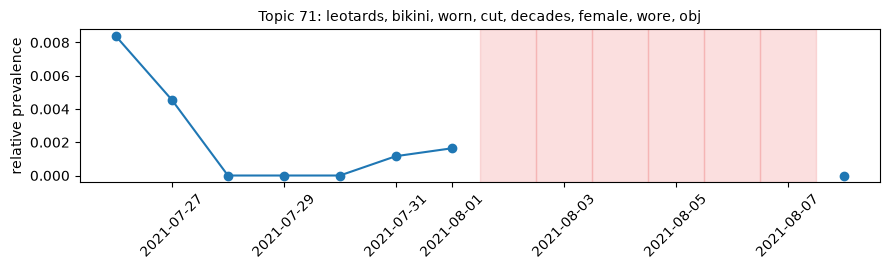

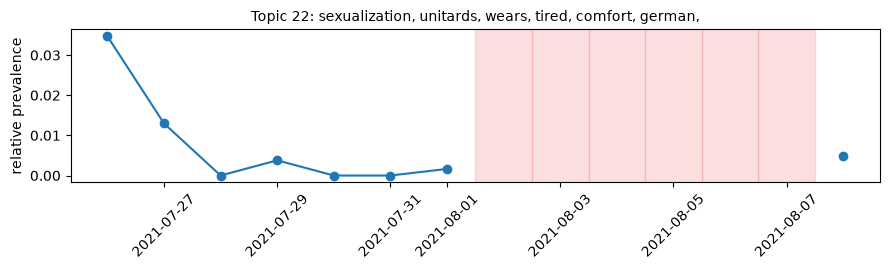

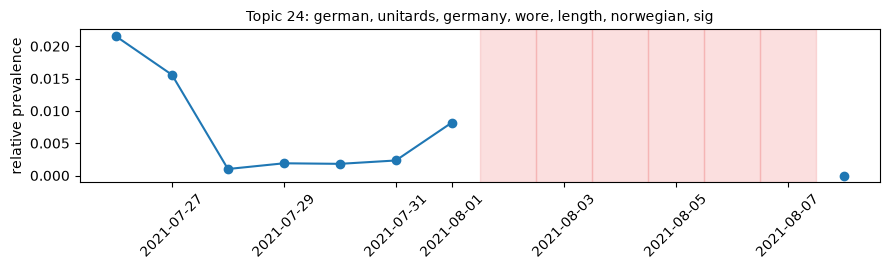

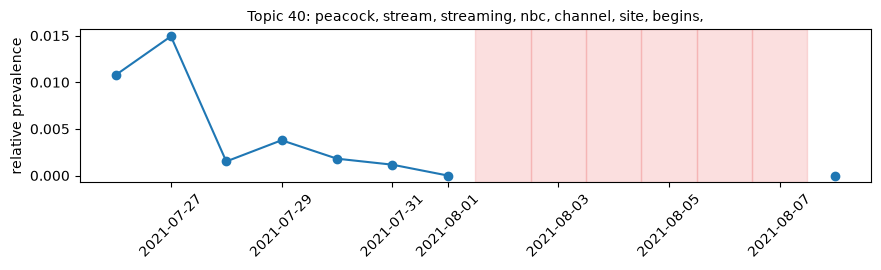

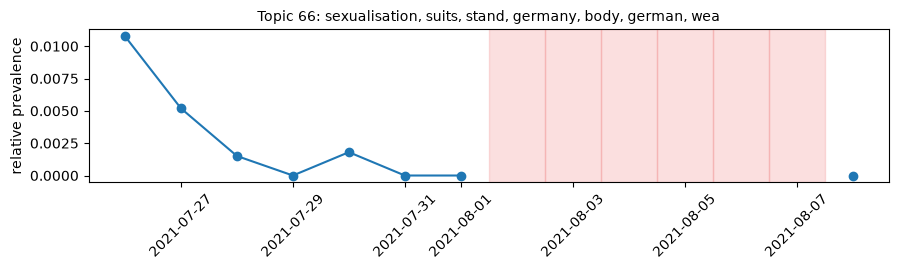

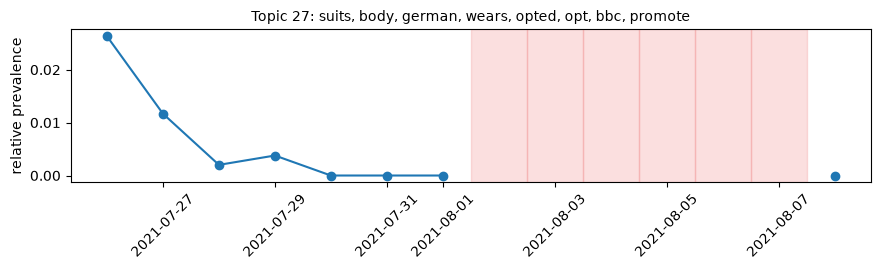

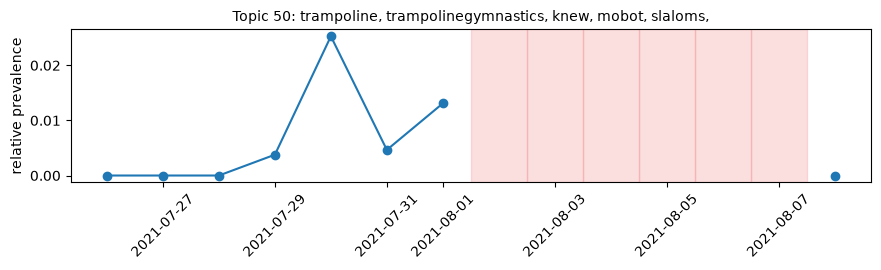

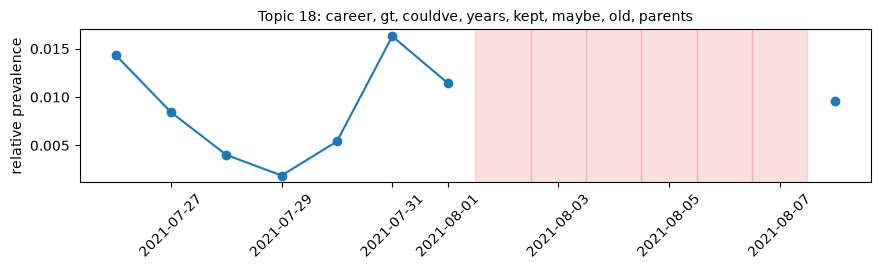

In [56]:
def prevalence(topic_id):
    values = {}
    for day in full_range:
        if day not in observed_days:
            values[day] = np.nan
            continue
        day_docs = gym[gym["day"] == day]
        if len(day_docs) < min_documents_per_day:
            values[day] = np.nan
            continue
        values[day] = (day_docs["topic"] == topic_id).sum() / len(day_docs)
    return pd.Series(values)

prevalence_table = pd.DataFrame({t: prevalence(t) for t in sorted(topic_words)})

display(prevalence_table[candidates].round(4))

for t in candidates:
    series = prevalence_table[t]
    plt.figure(figsize=(9, 2.8))
    plt.plot(pd.to_datetime(list(series.index)), series.values, "o-")
    for d in missing_days:
        plt.axvspan(pd.Timestamp(d) - pd.Timedelta(hours=12),
                    pd.Timestamp(d) + pd.Timedelta(hours=12),
                    color="lightcoral", alpha=0.25)
    plt.title(f"Topic {t}: {topic_words[t][:55]}", fontsize=10)
    plt.ylabel("relative prevalence")
    plt.xticks(rotation=45)
    plt.tight_layout(); plt.show()

---
## 11. Expanding-Window Validation

This procedure assesses **topic formability as documents accumulate**. It does not evidence
early detection of consumer interest.

The primary analysis is retrospective: the model is fitted on the complete corpus, so documents
from later dates inform the topic structure used to interpret earlier observations. The model is
therefore refitted at each collection date using only documents available up to that point.
Where a topic becomes identifiable later than its retrospective appearance, the cause is the
accumulation of documents required for cluster formation, not the emergence of the underlying
interest.

**Alignment.** Topics are matched by document membership. Two alternatives were examined and
rejected. Representative-term overlap fails because models fitted on different document pools
select different terms for the same topic. Centroid similarity also fails: averaged sentence
embeddings of gymnastics document sets lie close to the corpus mean, and at the first cut-off
all eight candidates returned similarities above 0.81 against only four clusters — a result that
cannot be correct. Document membership asks the operational question directly: were the
documents constituting a candidate topic grouped together using only the information available
at the time?

Visibility is not strictly monotonic. A topic identifiable at one cut-off may not be at the
next, as cluster boundaries shift with additional documents. The first date of identifiability
is therefore reported.

In [57]:
def topic_centroid(topic_id, frame=None):
    frame = gym if frame is None else frame
    docs = frame[frame["topic"] == topic_id]["clean"].tolist()
    if not docs:
        return None
    return np.asarray(embedder.encode(docs, show_progress_bar=False)).mean(axis=0)

def cosine(a, b):
    if a is None or b is None:
        return 0.0
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return 0.0 if na == 0 or nb == 0 else float(np.dot(a, b) / (na * nb))

reference_centroids = {t: topic_centroid(t) for t in candidates}

concentration_threshold = 0.5
minimum_documents = 10

expanding = []
for cutoff in observed_days:
    available = gym[gym["day"] <= cutoff]

    if len(available) < 300:
        expanding.append({"Cut-off": cutoff, "Documents": len(available),
                          "Topics": None, "Candidates Visible": "—",
                          "Concentration": "—"})
        continue

    um = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
              metric="cosine", random_state=seed)
    hd = HDBSCAN(min_cluster_size=min_topic_size, metric="euclidean",
                 cluster_selection_method="eom")
    m = BERTopic(embedding_model=embedder, umap_model=um, hdbscan_model=hd,
                 vectorizer_model=vectoriser, verbose=False)
    cut_labels = np.array(m.fit_transform(available["clean"].tolist())[0])

    cut_frame = available.copy()
    cut_frame["cut_topic"] = cut_labels
    n_cut_topics = len([t for t in set(cut_labels) if t != -1])

    visible, concentration = [], {}
    for t in candidates:
        members = set(gym[gym["topic"] == t]["clean"])
        present = cut_frame[cut_frame["clean"].isin(members)]

        if len(present) < minimum_documents:
            continue

        assigned = present[present["cut_topic"] != -1]
        if len(assigned) == 0:
            concentration[t] = 0.0
            continue

        largest = assigned["cut_topic"].value_counts().iloc[0]
        share = largest / len(present)
        concentration[t] = round(share, 2)

        if share >= concentration_threshold:
            visible.append(t)

    expanding.append({"Cut-off": cutoff, "Documents": len(available),
                      "Topics": n_cut_topics,
                      "Candidates Visible": str(visible) if visible else "none",
                      "Concentration": str(concentration) if concentration else "—"})

    print(f"{cutoff}: {len(available):>5,} documents, {n_cut_topics:>3} topics, "
          f"visible: {visible if visible else 'none'}")
    del m; gc.collect()

expanding = pd.DataFrame(expanding)
display(
    expanding.style
    .format({"Documents": "{:,.0f}", "Topics": "{:.0f}"}, na_rep="—")
    .set_properties(subset=["Candidates Visible", "Concentration"],
                    **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

detectability = []
for t in candidates:
    first_seen = None
    for _, row in expanding.iterrows():
        if isinstance(row["Candidates Visible"], str) and str(t) in row["Candidates Visible"]:
            first_seen = row["Cut-off"]
            break
    retro = prevalence_table[t].dropna()
    retro_start = retro.index[0] if len(retro) else None
    lag = ((pd.Timestamp(first_seen) - pd.Timestamp(retro_start)).days
           if first_seen and retro_start else None)
    detectability.append({"Topic": t, "Retrospective": retro_start,
                          "Prospective": first_seen, "Lag (days)": lag})

detectability = pd.DataFrame(detectability)
display(detectability.style.hide(axis="index"))

lags = detectability["Lag (days)"].dropna()
if len(lags):
    print(f"Mean detectability lag: {lags.mean():.1f} days "
          f"(range {lags.min():.0f} to {lags.max():.0f})")

2021-07-26:   838 documents,   4 topics, visible: [22, 24, 27, 18]
2021-07-27: 2,379 documents,  21 topics, visible: [71, 22, 24, 40, 66, 27, 18]
2021-07-28: 4,367 documents,  29 topics, visible: [71, 22, 24, 40, 66, 27, 18]
2021-07-29: 4,896 documents,  41 topics, visible: [71, 22, 24, 40, 66, 27, 18]
2021-07-30: 5,450 documents,  65 topics, visible: [71, 22, 24, 40, 66, 27, 18]
2021-07-31: 6,310 documents,  64 topics, visible: [22, 24, 40, 66, 27, 50, 18]
2021-08-01: 6,921 documents,  67 topics, visible: [71, 22, 24, 40, 66, 27, 50, 18]
2021-08-08: 7,129 documents,  73 topics, visible: [71, 22, 24, 40, 66, 27, 50, 18]


Cut-off,Documents,Topics,Candidates Visible,Concentration
2021-07-25,2,—,—,—
2021-07-26,838,4,"[22, 24, 27, 18]","{22: np.float64(1.0), 24: np.float64(0.94), 27: np.float64(1.0), 18: np.float64(1.0)}"
2021-07-27,"2,379",21,"[71, 22, 24, 40, 66, 27, 18]","{71: np.float64(0.93), 22: np.float64(1.0), 24: np.float64(0.98), 40: np.float64(0.91), 66: np.float64(1.0), 27: np.float64(1.0), 18: np.float64(0.76)}"
2021-07-28,"4,367",29,"[71, 22, 24, 40, 66, 27, 18]","{71: np.float64(0.93), 22: np.float64(0.88), 24: np.float64(0.95), 40: np.float64(0.97), 66: np.float64(0.9), 27: np.float64(1.0), 18: np.float64(1.0)}"
2021-07-29,"4,896",41,"[71, 22, 24, 40, 66, 27, 18]","{71: np.float64(0.93), 22: np.float64(0.92), 24: np.float64(0.87), 40: np.float64(0.97), 66: np.float64(0.95), 27: np.float64(0.98), 18: np.float64(1.0)}"
2021-07-30,"5,450",65,"[71, 22, 24, 40, 66, 27, 18]","{71: np.float64(0.93), 22: np.float64(0.67), 24: np.float64(0.93), 40: np.float64(0.95), 66: np.float64(0.9), 27: np.float64(0.91), 50: 0.0, 18: np.float64(0.65)}"
2021-07-31,"6,310",64,"[22, 24, 40, 66, 27, 50, 18]","{71: 0.0, 22: np.float64(0.92), 24: np.float64(0.96), 40: np.float64(0.95), 66: np.float64(0.86), 27: np.float64(0.96), 50: np.float64(0.95), 18: np.float64(0.88)}"
2021-08-01,"6,921",67,"[71, 22, 24, 40, 66, 27, 50, 18]","{71: np.float64(0.88), 22: np.float64(0.94), 24: np.float64(0.96), 40: np.float64(0.95), 66: np.float64(0.95), 27: np.float64(1.0), 50: np.float64(0.96), 18: np.float64(0.9)}"
2021-08-08,"7,129",73,"[71, 22, 24, 40, 66, 27, 50, 18]","{71: np.float64(1.0), 22: np.float64(1.0), 24: np.float64(1.0), 40: np.float64(1.0), 66: np.float64(1.0), 27: np.float64(1.0), 50: np.float64(1.0), 18: np.float64(1.0)}"


Topic,Retrospective,Prospective,Lag (days)
71,2021-07-26,2021-07-27,1
22,2021-07-26,2021-07-26,0
24,2021-07-26,2021-07-26,0
40,2021-07-26,2021-07-27,1
66,2021-07-26,2021-07-27,1
27,2021-07-26,2021-07-26,0
50,2021-07-26,2021-07-31,5
18,2021-07-26,2021-07-26,0


Mean detectability lag: 1.0 days (range 0 to 5)


---
## 12. Onset Assessment

An onset is the earliest usable observation at which a change becomes clearly observable,
provided the preceding observations support interpreting the change as newly observable. Where a
topic is already elevated at the beginning of the usable series, the change may have begun
before observation started and the onset is treated as **indeterminate**. No timing estimate is
produced in that case, since the apparent first observation would reflect the start of
collection rather than the start of the topic.

**Commensurability.** The two onset criteria are not strictly commensurable. The social media
criterion is defined relative to a topic's own observed maximum; the external criterion relative
to the variability of a prior baseline period. They identify different kinds of change, and the
interval between them should not be interpreted as a precise lead or lag. This compounds the
coverage difference: the external series includes a 45-day pre-observation baseline that the
social series does not.

In [58]:
onset = {}
for t in sorted(topic_words):
    series = prevalence_table[t].dropna()
    if len(series) < 2:
        onset[t] = None
        continue
    threshold = series.max() * 0.25
    if series.iloc[0] >= threshold:
        onset[t] = None
    else:
        risen = series[series >= threshold]
        onset[t] = risen.index[0] if len(risen) else None

observable = [t for t in candidates if onset[t] is not None]

onset_table = pd.DataFrame([
    {"Topic": t,
     "First usable value": round(prevalence_table[t].dropna().iloc[0], 4),
     "Maximum": round(prevalence_table[t].dropna().max(), 4),
     "Onset": onset[t] if onset[t] else "indeterminate"}
    for t in candidates])

display(onset_table.style.hide(axis="index"))
print(f"Onset observable for {len(observable)} of {len(candidates)} candidates")

Topic,First usable value,Maximum,Onset
71,0.008400,0.008400,indeterminate
22,0.034700,0.034700,indeterminate
24,0.021500,0.021500,indeterminate
40,0.010800,0.014900,indeterminate
66,0.010800,0.010800,indeterminate
27,0.026300,0.026300,indeterminate
50,0.000000,0.025300,2021-07-30
18,0.014400,0.016300,indeterminate


Onset observable for 1 of 8 candidates


---
## 13. External Comparison

Google Trends provides a normalised relative search-interest index between 0 and 100 within
the selected query, period and geography. It is not interpreted as a measure of search volume,
purchasing activity or demand.

Queries are derived by rule from each topic's representative terms and recorded before
retrieval, so the selection cannot be revised after inspecting the resulting series. Responses
are cached because Google Trends samples its query logs and repeat requests return differing
values; caching is therefore a reproducibility requirement.

**Conceptual validity.** A series exceeding a threshold evidences correspondence only where the
query denotes the same concept as the topic. Each query is assessed as valid, ambiguous or
invalid before retrieval, and correspondence is reported over valid queries only.

**Google Trends entities.** Where an appropriate disambiguated concept exists, an entity is used
in place of a search term. The term *peacock* denotes both the streaming service and the bird;
the entity resolves this. Topics 22 and 24 share the query *unitards* and therefore do not
constitute independent observations.

Comparisons are anchored on the observation window rather than on a focal competition. Under the
broadened scope there is no single focal event, and anchoring on one would privilege a date the
corpus does not centre on.

In [59]:
window_start = pd.Timestamp(min(observed_days))
trends_start = window_start - timedelta(days=45)
trends_end = pd.Timestamp(max(observed_days)) + timedelta(days=14)

too_general = {"olympic", "olympics", "tokyo", "gymnastics", "gymnast"}

queries = {}
for t in candidates:
    terms = [w.strip() for w in topic_words[t].split(",")]
    usable = [w for w in terms if len(w) >= 4 and w.lower() not in too_general]
    queries[t] = next((w for w in usable
                       if has_exact_word(w.lower(), proxy_terms)),
                      usable[0] if usable else None)

trends_entities = {
    40: "/g/11h582cpmh",
}

specification = pd.DataFrame([
    {"Topic": t, "Query": trends_entities.get(t, q),
     "Type": "entity" if t in trends_entities else "search term",
     "Geography": "worldwide", "Language": "en-US", "Aggregation": "daily",
     "Baseline": f"{trends_start.date()} to {(window_start - timedelta(days=1)).date()}",
     "Criterion": "baseline mean + 1.5 SD"}
    for t, q in queries.items()])
display(specification.style.hide(axis="index"))

# concept as the topic; generic terms may rise for unrelated reasons.
query_validity = {
    71: ("valid",     "denotes competitive gymnastics apparel"),
    22: ("valid",     "denotes the specific garment discussed in the topic"),
    24: ("valid",     "as above; duplicates the query for topic 22, so the two "
                      "do not constitute independent observations"),
    40: ("valid",     "Google Trends entity for the streaming service, "
                      "disambiguated from the bird"),
    66: ("invalid",   "generic verb, no consumer concept"),
    27: ("invalid",   "denotes business attire and legal proceedings more "
                      "frequently than gymnastics apparel"),
    50: ("ambiguous", "denotes both the apparatus as a consumer product and "
                      "the Olympic discipline"),
    18: ("invalid",   "generic term, unrelated to any consumer concept"),
}

validity_table = pd.DataFrame([
    {"Topic": t, "Query": trends_entities.get(t, queries.get(t)),
     "Validity": query_validity.get(t, ("unassessed", ""))[0],
     "Assessment": query_validity.get(t, ("", ""))[1]}
    for t in candidates])
display(
    validity_table.style
    .set_properties(subset=["Query", "Validity", "Assessment"],
                    **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

valid_queries = [t for t in candidates
                 if query_validity.get(t, ("unassessed",))[0] == "valid"]
print(f"Conceptually valid queries: {valid_queries}")

trends_data, trends_onset = {}, {}
for t, query in queries.items():
    if query is None:
        trends_onset[t] = None
        continue

    lookup = trends_entities.get(t, query)

    key = hashlib.md5(f"{lookup}|{trends_start}|{trends_end}".encode()).hexdigest()[:12]
    cache_file = cache_folder / f"trends_{key}.csv"

    try:
        if cache_file.exists():
            series = pd.read_csv(cache_file, index_col=0, parse_dates=True).iloc[:, 0]
        else:
            conn = TrendReq(hl="en-US", tz=0)
            conn.build_payload([lookup],
                               timeframe=f"{trends_start.date()} {trends_end.date()}")
            frame = conn.interest_over_time()
            frame = frame[frame["isPartial"] == False]
            series = frame[lookup].astype(float)
            series.to_frame().to_csv(cache_file)
            time.sleep(2)
    except Exception as problem:
        print(f"{lookup}: unavailable ({type(problem).__name__})")
        trends_onset[t] = None
        continue

    trends_data[t] = series
    baseline = series[series.index < window_start]
    threshold = baseline.mean() + 1.5 * baseline.std()
    exceeding = series[(series.index >= window_start) & (series > threshold)]
    trends_onset[t] = exceeding.index[0].date() if len(exceeding) else None

corresponding_valid = sum(1 for t in valid_queries if trends_onset.get(t) is not None)
print(f"\nExternal correspondence, valid queries only: "
      f"{corresponding_valid}/{len(valid_queries)}")
print("Topics with ambiguous or invalid queries are excluded: a series exceeding")
print("a threshold does not evidence correspondence where the query does not")
print("denote the concept represented by the topic.")

Topic,Query,Type,Geography,Language,Aggregation,Baseline,Criterion
71,leotards,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
22,unitards,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
24,unitards,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
40,/g/11h582cpmh,entity,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
66,wearing,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
27,suits,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
50,trampoline,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD
18,career,search term,worldwide,en-US,daily,2021-06-10 to 2021-07-24,baseline mean + 1.5 SD


Topic,Query,Validity,Assessment
71,leotards,valid,denotes competitive gymnastics apparel
22,unitards,valid,denotes the specific garment discussed in the topic
24,unitards,valid,"as above; duplicates the query for topic 22, so the two do not constitute independent observations"
40,/g/11h582cpmh,valid,"Google Trends entity for the streaming service, disambiguated from the bird"
66,wearing,invalid,"generic verb, no consumer concept"
27,suits,invalid,denotes business attire and legal proceedings more frequently than gymnastics apparel
50,trampoline,ambiguous,denotes both the apparatus as a consumer product and the Olympic discipline
18,career,invalid,"generic term, unrelated to any consumer concept"


Conceptually valid queries: [71, 22, 24, 40]

External correspondence, valid queries only: 4/4
Topics with ambiguous or invalid queries are excluded: a series exceeding
a threshold does not evidence correspondence where the query does not
denote the concept represented by the topic.


### 13.1 Onset status of the qualifying topic

In [60]:
print("Topic 40 Trends onset:", trends_onset.get(40))
print("Topic 40 Twitter onset:", onset.get(40))

Topic 40 Trends onset: 2021-07-25
Topic 40 Twitter onset: None


### 13.2 Paired visualisation

The upper panel shows relative topic prevalence; the lower shows relative search interest. The
shaded region marks the Google Trends baseline period, which precedes the Twitter observation
window. The external series therefore had an opportunity to register an earlier onset that the
social series did not.

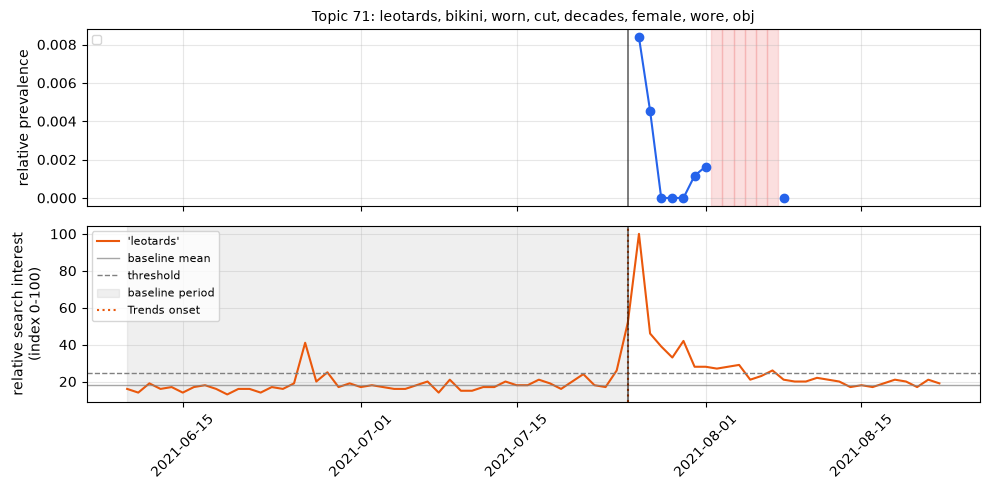

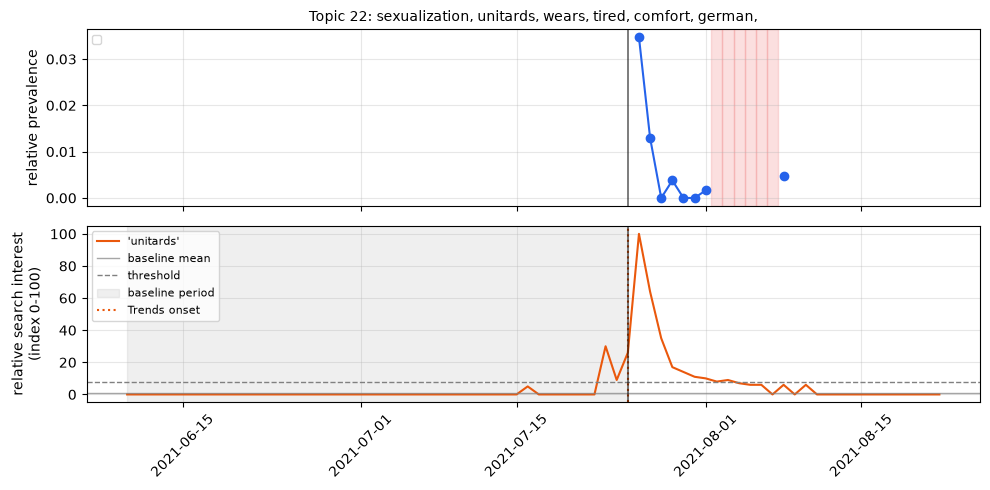

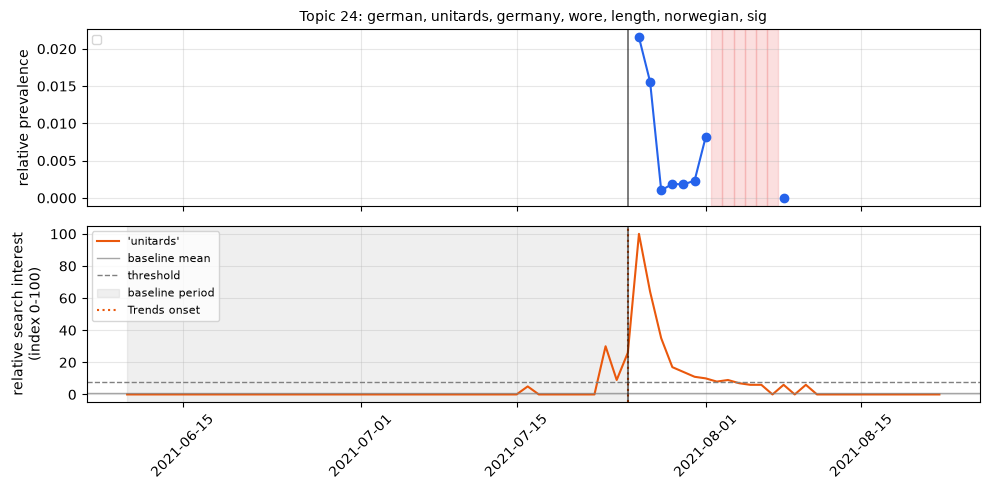

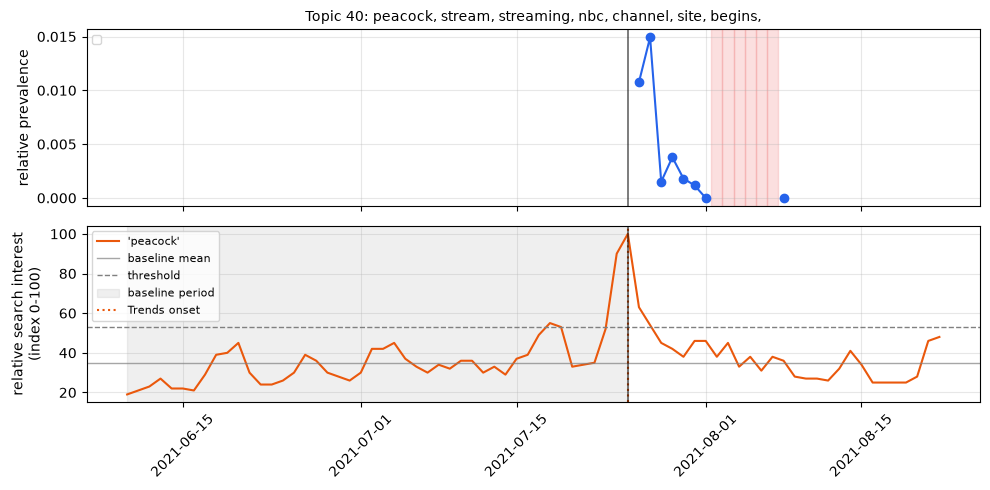

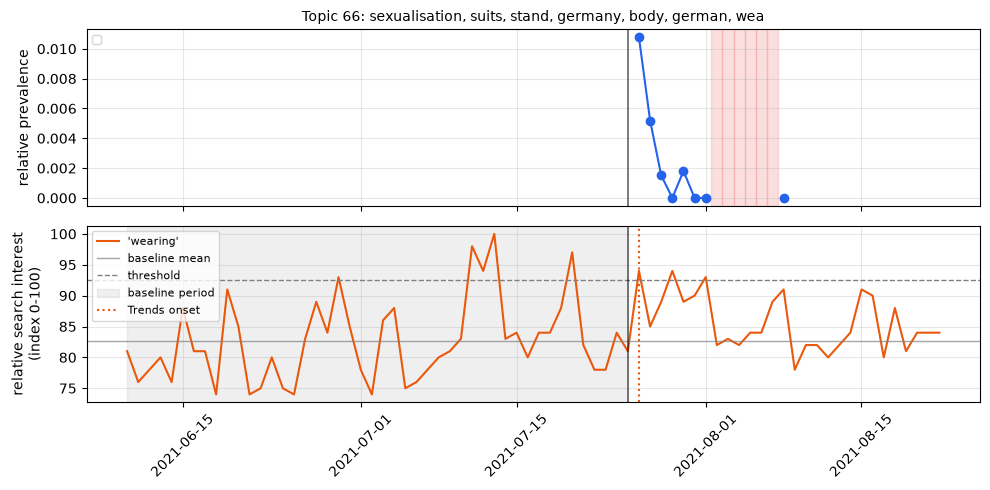

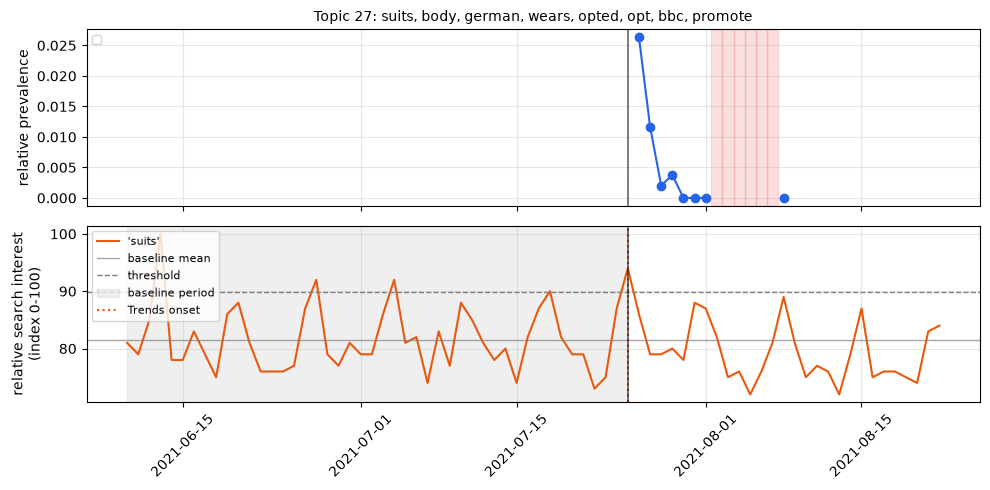

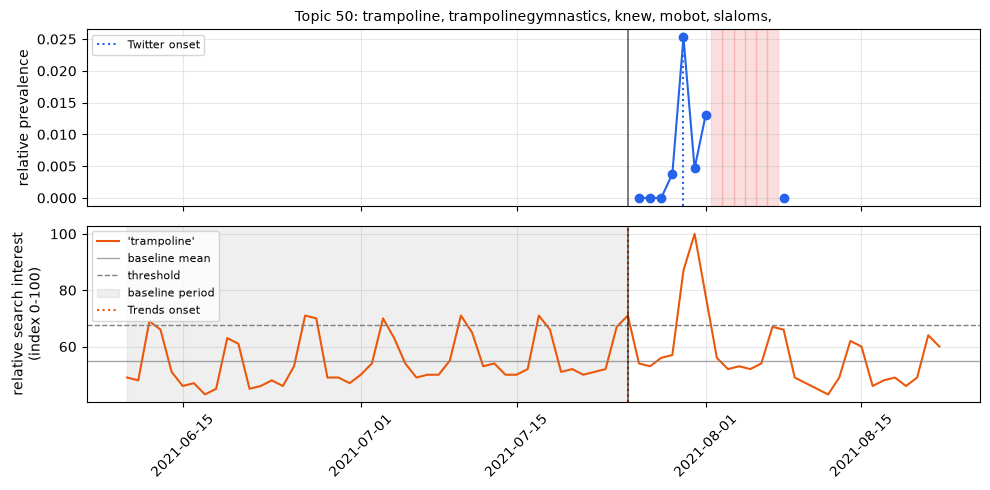

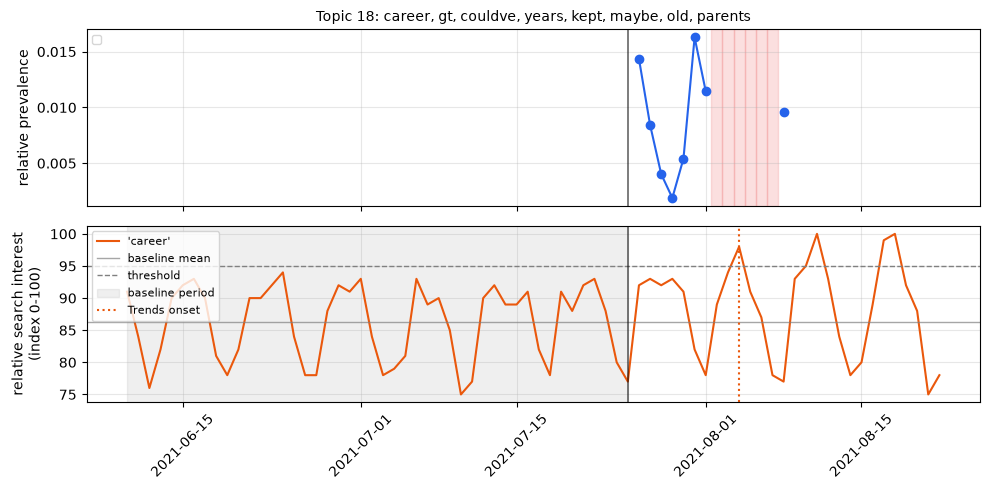

In [61]:
for t, series in trends_data.items():
    fig, (upper, lower) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

    p = prevalence_table[t]
    upper.plot(pd.to_datetime(list(p.index)), p.values, "o-", color="#2563eb")
    upper.set_ylabel("relative prevalence")
    upper.grid(alpha=0.3)
    for d in missing_days:
        upper.axvspan(pd.Timestamp(d) - pd.Timedelta(hours=12),
                      pd.Timestamp(d) + pd.Timedelta(hours=12),
                      color="lightcoral", alpha=0.25)
    if onset[t] is not None:
        upper.axvline(pd.Timestamp(onset[t]), color="#2563eb",
                      linestyle=":", label="Twitter onset")

    baseline = series[series.index < window_start]
    lower.plot(series.index, series.values, color="#ea580c",
               label=f"'{queries[t]}'")
    lower.axhline(baseline.mean(), color="grey", linewidth=1, alpha=0.7,
                  label="baseline mean")
    lower.axhline(baseline.mean() + 1.5 * baseline.std(), color="grey",
                  linestyle="--", linewidth=1, label="threshold")
    lower.axvspan(trends_start, window_start, color="grey", alpha=0.12,
                  label="baseline period")
    lower.set_ylabel("relative search interest\n(index 0-100)")
    lower.grid(alpha=0.3)
    if trends_onset[t] is not None:
        lower.axvline(pd.Timestamp(trends_onset[t]), color="#ea580c",
                      linestyle=":", label="Trends onset")

    for axis in (upper, lower):
        axis.axvline(window_start, color="black", linewidth=1.2, alpha=0.6)

    upper.set_title(f"Topic {t}: {topic_words[t][:55]}", fontsize=10)
    upper.legend(fontsize=8, loc="upper left")
    lower.legend(fontsize=8, loc="upper left")
    plt.xticks(rotation=45)
    plt.tight_layout(); plt.show()

---
## 14. Lead or Lag Assessment

An estimate is produced only where onsets are observable in both series. Where either cannot
be established, the relationship remains indeterminate and no value is forced from the available
observations. Results are reported per topic rather than aggregated, since averaging would
combine cases indicating opposite orderings. Query validity is recorded alongside each result.

In [62]:
results = []
for t in candidates:
    twitter_onset = onset[t]
    google_onset = trends_onset.get(t)

    if twitter_onset is None:
        lead, interpretation = None, "Twitter onset indeterminate"
    elif google_onset is None:
        lead, interpretation = None, "no corresponding external change"
    else:
        lead = (pd.Timestamp(google_onset) - pd.Timestamp(twitter_onset)).days
        interpretation = ("Twitter earlier" if lead > 0 else
                          "Trends earlier" if lead < 0 else "same date")

    results.append({"Topic": t, "Query": trends_entities.get(t, queries.get(t)),
                    "Query Validity": query_validity.get(t, ("unassessed",))[0],
                    "Twitter Onset": twitter_onset,
                    "Trends Onset": google_onset,
                    "Lead (days)": lead, "Interpretation": interpretation})

results = pd.DataFrame(results)
display(results.style.hide(axis="index"))

estimated = results[results["Lead (days)"].notna()]
print(f"Lead or lag estimated for {len(estimated)} of {len(results)} candidates")
for _, r in estimated.iterrows():
    print(f"   Topic {r['Topic']} ({r['Query']}): "
          f"{r['Lead (days)']:+.0f} days — {r['Interpretation']}")

estimated_valid = estimated[estimated["Query Validity"] == "valid"]
print(f"\nOf these, {len(estimated_valid)} derive from a conceptually valid query.")
print("The two onset criteria are not strictly commensurable: the social media")
print("criterion is relative to a topic's own maximum, the external criterion to")
print("the variability of a prior baseline period.")

Topic,Query,Query Validity,Twitter Onset,Trends Onset,Lead (days),Interpretation
71,leotards,valid,None,2021-07-25,nan,Twitter onset indeterminate
22,unitards,valid,None,2021-07-25,nan,Twitter onset indeterminate
24,unitards,valid,None,2021-07-25,nan,Twitter onset indeterminate
40,/g/11h582cpmh,valid,None,2021-07-25,nan,Twitter onset indeterminate
66,wearing,invalid,None,2021-07-26,nan,Twitter onset indeterminate
27,suits,invalid,None,2021-07-25,nan,Twitter onset indeterminate
50,trampoline,ambiguous,2021-07-30,2021-07-25,-5.000000,Trends earlier
18,career,invalid,None,2021-08-04,nan,Twitter onset indeterminate


Lead or lag estimated for 1 of 8 candidates
   Topic 50 (trampoline): -5 days — Trends earlier

Of these, 0 derive from a conceptually valid query.
The two onset criteria are not strictly commensurable: the social media
criterion is relative to a topic's own maximum, the external criterion to
the variability of a prior baseline period.


---
## 15. Published Baseline: BERTrend

Comparison against a simpler algorithm establishes whether a method is computationally
justified, but not whether it contributes beyond existing published work. BERTrend (Boutaleb,
Picault & Grosjean, 2024) is selected as the literature baseline because it addresses the same
task using the same underlying topic model, so differences reflect method rather than model
choice.

**Method.** The corpus is divided into daily slices and BERTopic fitted on each independently.
Topics are merged across slices where cosine similarity between topic embeddings exceeds a
threshold, with the embedding of a topic's first occurrence retained to prevent drift. Topic
popularity is initialised at the document count, incremented when a topic receives new
documents, and decayed exponentially when it does not.

**Documented deviations.** The published method discards documents under 100 Latin characters as
noise; tweets are short and applying this filter would remove most of the corpus, so it is not
applied. The published `min_cluster_size` is 2; the published corpora contain hundreds of
thousands of documents whereas daily slices here contain 200 to 2,000, so 5 is used.

**Evaluation note.** The BERTrend authors state that no established metrics exist for comparing
weak signal detection and that coherence and diversity are unsuitable for the task. The
comparison therefore establishes **topic recovery across methods** rather than comparative
detection performance.

In [63]:
print("embedding corpus for slice-level analysis")
all_embeddings = np.asarray(embedder.encode(gym["clean"].tolist(),
                                            show_progress_bar=False))
gym_indexed = gym.reset_index(drop=True)

tracked, history, next_id = {}, [], 0

for day in observed_days:
    mask = (gym_indexed["day"] == day).values
    slice_docs = gym_indexed[mask]
    slice_emb = all_embeddings[mask]

    if len(slice_docs) < min_documents_per_day:
        print(f"{day}: {len(slice_docs)} documents, slice below threshold")
        continue

    um = UMAP(n_neighbors=min(15, len(slice_docs) - 1), n_components=5,
              min_dist=0.0, metric="cosine", random_state=seed)
    hd = HDBSCAN(min_cluster_size=slice_min_cluster, min_samples=1,
                 metric="euclidean", cluster_selection_method="eom")
    m = BERTopic(embedding_model=embedder, umap_model=um, hdbscan_model=hd,
                 vectorizer_model=vectoriser, verbose=False)
    slice_labels = np.array(m.fit_transform(slice_docs["clean"].tolist(),
                                            slice_emb)[0])

    slice_topics = {}
    for t in set(slice_labels):
        if t == -1:
            continue
        slice_topics[t] = {
            "centroid": slice_emb[slice_labels == t].mean(axis=0),
            "n_docs": int((slice_labels == t).sum()),
            "terms": ", ".join(w for w, _ in m.get_topic(t)[:8])}

    updated = set()
    for t, info in slice_topics.items():
        best_id, best_sim = None, 0.0
        for tid, tracked_info in tracked.items():
            sim = cosine(info["centroid"], tracked_info["embedding"])
            if sim > best_sim:
                best_id, best_sim = tid, sim

        if best_sim >= merge_threshold:
            tracked[best_id]["popularity"] += info["n_docs"]
            tracked[best_id]["last_update"] = day
            updated.add(best_id)
        else:
            tracked[next_id] = {"terms": info["terms"],
                                "embedding": info["centroid"],
                                "popularity": float(info["n_docs"]),
                                "last_update": day}
            updated.add(next_id)
            next_id += 1

    for tid, info in tracked.items():
        if tid not in updated:
            gap = (pd.Timestamp(day) - pd.Timestamp(info["last_update"])).days
            info["popularity"] *= np.exp(-decay_lambda * gap ** 2)

    for tid, info in tracked.items():
        history.append({"day": day, "topic": tid,
                        "popularity": info["popularity"], "terms": info["terms"]})

    print(f"{day}: {len(slice_docs):>5,} documents, {len(slice_topics):>3} slice topics, "
          f"{len(tracked):>3} tracked")
    del m; gc.collect()

bertrend = pd.DataFrame(history)
print(f"\nTracked topics: {len(tracked)}")

embedding corpus for slice-level analysis
2021-07-25: 2 documents, slice below threshold
2021-07-26:   836 documents,  67 slice topics,  15 tracked
2021-07-27: 1,541 documents, 112 slice topics,  26 tracked
2021-07-28: 1,988 documents, 135 slice topics,  43 tracked
2021-07-29:   529 documents,  42 slice topics,  46 tracked
2021-07-30:   554 documents,  42 slice topics,  50 tracked
2021-07-31:   860 documents,  57 slice topics,  53 tracked
2021-08-01:   611 documents,  48 slice topics,  56 tracked
2021-08-08:   208 documents,   9 slice topics,  58 tracked

Tracked topics: 58


### 15.1 Signal classification

Classification uses rolling percentiles. Below the tenth percentile a topic is noise; above
the median it is a strong signal; between the two it is a weak signal only where a linear
regression over the window has positive slope. The slope test distinguishes an emerging topic
from one that was popular and is declining.

In [64]:
classified = []
for day in sorted(bertrend["day"].unique()):
    window_begin = pd.Timestamp(day) - pd.Timedelta(days=window_days)
    window = bertrend[(pd.to_datetime(bertrend["day"]) > window_begin)
                      & (pd.to_datetime(bertrend["day"]) <= pd.Timestamp(day))]
    if len(window) < 3:
        continue

    p10 = np.percentile(window["popularity"], 10)
    p50 = np.percentile(window["popularity"], 50)

    for _, row in bertrend[bertrend["day"] == day].iterrows():
        popularity = row["popularity"]
        if popularity < p10:
            signal = "noise"
        elif popularity > p50:
            signal = "strong"
        else:
            series = window[window["topic"] == row["topic"]].sort_values("day")
            if len(series) >= 2:
                slope = linregress(range(len(series)), series["popularity"]).slope
                signal = "weak" if slope > 0 else "noise"
            else:
                signal = "weak"
        classified.append({"day": day, "topic": row["topic"],
                           "popularity": popularity, "signal": signal,
                           "terms": row["terms"]})

bertrend_signals = pd.DataFrame(classified)

counts = bertrend_signals.pivot_table(index="day", columns="signal",
                                      values="topic", aggfunc="count").fillna(0)
display(counts.astype(int))

signal,noise,strong,weak
day,,,
2021-07-26,0,7,8
2021-07-27,4,12,10
2021-07-28,9,23,11
2021-07-29,16,26,4
2021-07-30,19,25,6
2021-07-31,20,25,8
2021-08-01,20,27,9
2021-08-08,6,29,23


### 15.2 Comparison

Topics are matched by centroid similarity, which is appropriate here because both sides are
full-corpus topic representations rather than one broad and one fine.

In [65]:
comparison_rows = []
for t in candidates:
    reference = reference_centroids[t]

    best_id, best_sim = None, 0.0
    for tid, info in tracked.items():
        sim = cosine(reference, info["embedding"])
        if sim > best_sim:
            best_id, best_sim = tid, sim

    prospective = detectability[detectability["Topic"] == t]["Prospective"]
    framework_date = prospective.iloc[0] if len(prospective) else None

    if best_sim < match_threshold:
        comparison_rows.append({"Topic": t, "BERTrend Topic": None,
                                "Similarity": round(best_sim, 3),
                                "BERTrend Flagged": None,
                                "Framework Detection": framework_date,
                                "Difference (days)": None,
                                "Framework Onset": onset[t] or "indeterminate"})
        continue

    flagged = bertrend_signals[(bertrend_signals["topic"] == best_id)
                               & (bertrend_signals["signal"].isin(["weak", "strong"]))]
    bertrend_date = flagged["day"].min() if len(flagged) else None
    difference = ((pd.Timestamp(bertrend_date) - pd.Timestamp(framework_date)).days
                  if bertrend_date and framework_date else None)

    comparison_rows.append({"Topic": t, "BERTrend Topic": best_id,
                            "Similarity": round(best_sim, 3),
                            "BERTrend Flagged": bertrend_date,
                            "Framework Detection": framework_date,
                            "Difference (days)": difference,
                            "Framework Onset": onset[t] or "indeterminate"})

baseline_comparison = pd.DataFrame(comparison_rows)
display(baseline_comparison.style.hide(axis="index"))

recovered = baseline_comparison["BERTrend Topic"].notna().sum()
flagged_first_day = (baseline_comparison["BERTrend Flagged"]
                     == min(observed_days[1:])).sum()
print(f"Recovered by BERTrend          : {recovered} of {len(candidates)}")
print(f"Flagged on first usable date   : {flagged_first_day}")
print(f"Framework onset indeterminate  : "
      f"{(baseline_comparison['Framework Onset'] == 'indeterminate').sum()}")

Topic,BERTrend Topic,Similarity,BERTrend Flagged,Framework Detection,Difference (days),Framework Onset
71,10,0.972000,2021-07-26,2021-07-27,-1,indeterminate
22,7,0.947000,2021-07-26,2021-07-26,0,indeterminate
24,1,0.822000,2021-07-26,2021-07-26,0,indeterminate
40,23,0.916000,2021-07-27,2021-07-27,0,indeterminate
66,1,0.875000,2021-07-26,2021-07-27,-1,indeterminate
27,1,0.997000,2021-07-26,2021-07-26,0,indeterminate
50,0,0.779000,2021-07-26,2021-07-31,-5,2021-07-30
18,0,0.812000,2021-07-26,2021-07-26,0,indeterminate


Recovered by BERTrend          : 8 of 8
Flagged on first usable date   : 7
Framework onset indeterminate  : 7


---
## 16. Two-Coder Qualification

The behavioural screen in §9 nominates candidate topics but does not establish consumer
interest. Final qualification requires manual review by two coders working independently.

Topic modelling is unsupervised and admits no ground truth, so classification metrics cannot be
applied to it. The screening decision is the one component of the pipeline where a reference
standard can be constructed, and precision and recall are therefore reported for that component
only.

**Sampling.** Fifteen documents are drawn per candidate topic, giving a qualification proportion
with a resolution of approximately 0.07. Documents from non-candidate topics are included so the
sample is not composed entirely of positive cases and the screen's false positive rate can be
estimated. The sheet is shuffled before distribution so coders cannot infer the screen's
prediction from a document's position.

**Categories.** Three labels are distinguished, separating consumer interest from product
mentions and from descriptions of athletes' behaviour. The distinction is necessary because a
topic may contain extensive product vocabulary while consisting entirely of reporting: a
headline stating that a team wore particular apparel describes athletes' behaviour, not consumer
interest in that apparel. Only documents labelled 2 contribute to qualification.

The coding instructions are written to disk alongside the sheet, so that the criteria applied
are recorded rather than conveyed informally.

In [66]:
# DISABLED after coding. Re-enable only to regenerate the instrument, which
# would overwrite the labelled sheet.

'''rng = np.random.default_rng(seed)

sample_rows = []
for t in candidates:
    topic_docs = gym[gym["topic"] == t]
    for _, r in topic_docs.sample(min(15, len(topic_docs)),
                                  random_state=seed).iterrows():
        sample_rows.append({"topic": t, "text": r["text"], "screen_flagged": 1})

non_candidates = [t for t in topic_words if t not in candidates]
for t in rng.choice(non_candidates, size=min(10, len(non_candidates)),
                    replace=False):
    topic_docs = gym[gym["topic"] == t]
    for _, r in topic_docs.sample(min(3, len(topic_docs)),
                                  random_state=seed).iterrows():
        sample_rows.append({"topic": int(t), "text": r["text"], "screen_flagged": 0})

coding_sheet = (pd.DataFrame(sample_rows)
                .sample(frac=1, random_state=seed)
                .reset_index(drop=True))
coding_sheet["rater_1"] = ""
coding_sheet["rater_2"] = ""

coding_sheet.to_csv(out_folder / "coding_sheet.csv", index=False)

# mentions and from descriptions of athletes' behaviour
instructions = """CODING INSTRUCTIONS

Label each document 2, 1 or 0.

2 - CONSUMER INTEREST
    The author expresses their own searching, wanting, buying, using, price or
    brand interest, viewing, or participation.
      "where can I buy one of those unitards"
      "next olympics can you add streaming bundles? I'd pay a decent amount"
      "thinking of signing my daughter up for gymnastics classes"

1 - PRODUCT MENTION
    A product, brand or service is present, but the author expresses no
    consumer engagement with it.
      "those unitards are really well designed"
      "the Nike leotards look different this year"

0 - DESCRIPTION OR REPORTING
    Describes an event, athlete behaviour, competition result or news.
      "German Olympic gymnastics team, tired of 'sexualization,' wears unitards"
      "For decades, female gymnasts have worn bikini-cut leotards"
      "Hashimoto wins gold in the all-around final"

The distinction between 2 and 0 is whether the AUTHOR engages as a consumer or
reports what someone else did. A headline describing what athletes wore is 0,
however much product vocabulary it contains.

Code independently. Do not discuss while coding. Do not sort the file.
"""

(out_folder / "coding_instructions.txt").write_text(instructions)

print(f"Coding instrument: {len(coding_sheet)} documents")
print(f"   {out_folder}/coding_sheet.csv")
print(f"   {out_folder}/coding_instructions.txt")'''

'rng = np.random.default_rng(seed)\n\nsample_rows = []\nfor t in candidates:\n    topic_docs = gym[gym["topic"] == t]\n    for _, r in topic_docs.sample(min(15, len(topic_docs)),\n                                  random_state=seed).iterrows():\n        sample_rows.append({"topic": t, "text": r["text"], "screen_flagged": 1})\n\nnon_candidates = [t for t in topic_words if t not in candidates]\nfor t in rng.choice(non_candidates, size=min(10, len(non_candidates)),\n                    replace=False):\n    topic_docs = gym[gym["topic"] == t]\n    for _, r in topic_docs.sample(min(3, len(topic_docs)),\n                                  random_state=seed).iterrows():\n        sample_rows.append({"topic": int(t), "text": r["text"], "screen_flagged": 0})\n\ncoding_sheet = (pd.DataFrame(sample_rows)\n                .sample(frac=1, random_state=seed)\n                .reset_index(drop=True))\ncoding_sheet["rater_1"] = ""\ncoding_sheet["rater_2"] = ""\n\ncoding_sheet.to_csv(out_folder / "coding

The instrument is disabled after distribution. Regenerating it would overwrite the labelled
sheet, which is the only artefact in the project that cannot be reproduced by re-executing code.

### 16.1 Agreement, screen evaluation and qualification

**Agreement.** Cohen's kappa is computed with linear weighting, since the three categories are
ordered and a disagreement between adjacent labels is less serious than one between extremes.

Kappa is reported alongside the label distribution and per-category agreement rather than alone.
Where one category dominates, raw agreement is inflated by the ease of agreeing on that
category, and an aggregate figure can obscure disagreement about the construct of interest.
Reporting agreement separately for each label makes the distinction visible.

**Screen evaluation.** Where coders agree, the agreed label is treated as the reference standard.
Precision and recall are computed with label 2 as the positive class, since qualification depends
on that label alone.

**Qualification.** A topic qualifies where at least 25% of its agreed documents are labelled 2.
The threshold was stated in the methodology before the coded results were available, and the
observed proportion is reported for every topic so that an alternative threshold may be applied.

In [67]:
coded = pd.read_csv(out_folder / "coding_sheet.csv")
coded = coded.dropna(subset=["rater_1", "rater_2"])

if len(coded) == 0:
    print("Coding not yet complete.")
    qualified = []
else:
    from sklearn.metrics import cohen_kappa_score, precision_recall_fscore_support

    rater_1 = coded["rater_1"].astype(int)
    rater_2 = coded["rater_2"].astype(int)

    kappa = cohen_kappa_score(rater_1, rater_2, weights="linear")
    print(f"Documents coded        : {len(coded)}")
    print(f"Cohen's kappa (linear) : {kappa:.3f}")
    print(f"Raw agreement          : {(rater_1 == rater_2).mean():.1%}")

    agreed = coded[rater_1 == rater_2].copy()
    agreed["label"] = agreed["rater_1"].astype(int)

    print("\nAgreed label distribution")
    for label, name in [(2, "consumer interest"), (1, "product mention"),
                        (0, "description or reporting")]:
        print(f"   {label} {name:<26}: {(agreed['label'] == label).sum()}")

    print("\nAgreement by category")
    for label, name in [(2, "consumer interest"), (1, "product mention"),
                        (0, "description or reporting")]:
        either = coded[(rater_1 == label) | (rater_2 == label)]
        both = either[either["rater_1"].astype(int) == either["rater_2"].astype(int)]
        rate = len(both) / len(either) if len(either) else float("nan")
        print(f"   {label} {name:<26}: {len(both):>3} of {len(either):>3} "
              f"({rate:.0%}) where either coder used the label")

    precision, recall, f1, _ = precision_recall_fscore_support(
        (agreed["label"] == 2).astype(int),
        agreed["screen_flagged"].astype(int),
        average="binary", zero_division=0)
    print(f"\nScreen evaluated against {len(agreed)} agreed labels")
    print(f"   precision {precision:.2f}   recall {recall:.2f}   F1 {f1:.2f}")

    qualification_threshold = 0.25
    qualification = []
    for t in candidates:
        topic_coded = agreed[agreed["topic"] == t]
        if len(topic_coded) == 0:
            continue
        n_consumer = int((topic_coded["label"] == 2).sum())
        n_mention = int((topic_coded["label"] == 1).sum())
        proportion = n_consumer / len(topic_coded)
        qualification.append({
            "Topic": t, "Coded": len(topic_coded),
            "Consumer interest": n_consumer, "Product mention": n_mention,
            "Proportion": round(proportion, 2),
            "Qualifies": "Yes" if proportion >= qualification_threshold else "No"})

    qualification = pd.DataFrame(qualification)
    display(qualification.style.hide(axis="index"))

    qualified = qualification[qualification["Qualifies"] == "Yes"]["Topic"].tolist()
    print(f"Qualifying topics: {qualified if qualified else 'none'}")
    qualification.to_csv(out_folder / "qualification.csv", index=False)

Documents coded        : 150
Cohen's kappa (linear) : 0.461
Raw agreement          : 87.3%

Agreed label distribution
   2 consumer interest         : 5
   1 product mention           : 4
   0 description or reporting  : 122

Agreement by category
   2 consumer interest         :   5 of  15 (33%) where either coder used the label
   1 product mention           :   4 of  14 (29%) where either coder used the label
   0 description or reporting  : 122 of 140 (87%) where either coder used the label

Screen evaluated against 131 agreed labels
   precision 0.05   recall 1.00   F1 0.09


Topic,Coded,Consumer interest,Product mention,Proportion,Qualifies
71,14,0,2,0.000000,No
22,13,0,0,0.000000,No
24,10,0,2,0.000000,No
40,13,5,0,0.380000,Yes
66,14,0,0,0.000000,No
27,15,0,0,0.000000,No
50,15,0,0,0.000000,No
18,9,0,0,0.000000,No


Qualifying topics: [40]


Agreement is markedly uneven across categories. Coders agreed on 87% of documents where either
used the description label, but on only 33% where either used the consumer interest label and
29% for product mention. Raw agreement of 87.3% therefore reflects consensus about what does not
constitute consumer interest rather than about what does, and the weighted kappa of 0.461 is a
more faithful summary than the raw figure.

The agreed label distribution is heavily imbalanced: 122 of 131 agreed documents are
descriptions or reporting, against five consumer interest and four product mentions. This
imbalance inflates the chance-agreement baseline and depresses kappa, a known property of the
statistic rather than evidence of careless coding — the coders differed on only nineteen of 150
documents.

The screen identified every consumer interest document in the agreed sample but flagged
substantially more, consistent with its stated role as a nomination rather than classification
procedure. The precision of this estimate is examined in §16.4.

One topic qualifies under the stated criterion.

### 16.2 Disagreement analysis

Disagreements are examined for systematic pattern rather than reported only in aggregate. A
concentration on particular category boundaries, or within particular topics, indicates where
the coding scheme is underspecified — which is more informative for replication than the
agreement statistic alone, and determines whether the disagreement bears on the qualification
outcome.

In [68]:
disagreed = coded[coded["rater_1"].astype(int) != coded["rater_2"].astype(int)]

print(f"{len(disagreed)} disagreements of {len(coded)} documents\n")
print("Disagreement pattern by label pair")
print(disagreed.groupby(["rater_1", "rater_2"]).size().to_string())

print("\nDisagreements by topic")
print(disagreed.groupby("topic").size().sort_values(ascending=False).to_string())

print("\nExamples")
for _, r in disagreed.head(8).iterrows():
    print(f"\n[{r['rater_1']} vs {r['rater_2']}] topic {r['topic']}: "
          f"{str(r['text'])[:95]}")

19 disagreements of 150 documents

Disagreement pattern by label pair
rater_1  rater_2
0        1          3
         2          7
1        0          6
         2          1
2        0          2

Disagreements by topic
topic
18    6
24    5
22    2
40    2
54    2
66    1
71    1

Examples

[0 vs 2] topic 18: Everyday I think about what would've happened if I kept seriously training in gymnastics and di

[1 vs 0] topic 22: Love seeing more of this
#Feminism
#SportsNotSexualization
Wearing unitards, German gymnasts pr

[1 vs 0] topic 22: #Tokyo #Olympics2020: #German team debuts unitards to protest ‘#sexualisation in #gymnastics’



[0 vs 2] topic 18: There's a 32 year old competing in the gymnastics final and so I have now convinced myself that

[1 vs 0] topic 24: Racism for the Gold! 

@Olympics allowed the German gymnastics team to debut a full-length leot

[1 vs 0] topic 24: @catnip In not quite related news, I hope this decision by Germany's gymnasts is the start of s

[1 vs 0] t

Nineteen of 150 documents were coded differently. The disagreements are systematic in two
respects.

**By category boundary.** Nine concern the 0–2 boundary, the full width of the ordered scale and
therefore the most consequential form of disagreement. A further nine concern the 0–1 boundary,
and one the 1–2 boundary.

**By topic.** Six fall in topic 18 and five in topic 24, together accounting for eleven of the
nineteen. Topics 27 and 50 produced no disagreement at all.

The content explains the pattern. Disagreements in topic 18 concern retrospective or
hypothetical participation — *"what would have happened if I kept training"*, *"11-year-old me
watching the Olympics: I want to be a gymnast"*. One coder read these as expressing participation
interest, the other as reflection without intent. The instructions list participation as an
indicator without specifying whether it must be actual or imagined.

Disagreements in topics 22 and 24 concern shared news content carrying the sharer's own
commentary — *"Love seeing more of this"* prefixed to a headline. One coder treated the added
commentary as engagement with the product, the other treated the document as reporting.

Both boundaries are genuinely ambiguous under the scheme as written. Their effect on the
qualification outcome is assessed in §16.3.

### 16.3 Sensitivity of the qualification criteria

Two decisions were adopted without established precedent: the 25% threshold, and the use of
agreed labels only. Neither has a settled standard, so both are tested rather than asserted.

**Threshold.** The criterion operationalises the distinction between a topic representing
consumer attention and one where consumer expression is incidental. It was stated in the
methodology before the coded results were available, so it could not be fitted to the outcome.

**Disagreement.** Nineteen of 150 documents were coded differently. Rather than resolve these by
discussion — which, conducted after the outcome is known, risks motivated adjudication —
qualification is recomputed under five resolution rules spanning the range of defensible
choices.

In [69]:
print("EFFECT OF EXCLUDING DISAGREEMENTS ON TOPIC PROPORTIONS\n")
print(f"{'Topic':>6}{'Sampled':>10}{'Agreed':>9}{'Dropped':>9}"
      f"{'% dropped':>12}{'Proportion':>13}")
print("-" * 60)

for t in candidates:
    all_rows = coded[coded["topic"] == t]
    if len(all_rows) == 0:
        continue
    agreed_rows = all_rows[all_rows["rater_1"].astype(int)
                           == all_rows["rater_2"].astype(int)]
    dropped = len(all_rows) - len(agreed_rows)
    proportion = ((agreed_rows["rater_1"].astype(int) == 2).sum()
                  / len(agreed_rows)) if len(agreed_rows) else float("nan")
    print(f"{t:>6}{len(all_rows):>10}{len(agreed_rows):>9}{dropped:>9}"
          f"{dropped/len(all_rows)*100:>11.0f}%{proportion:>13.2f}")


print("\n\nTHRESHOLD VARIATION\n")
for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.33, 0.40, 0.50]:
    passing = qualification[qualification["Proportion"] >= threshold]["Topic"].tolist()
    marker = "  <- adopted" if abs(threshold - 0.25) < 1e-9 else ""
    print(f"threshold {threshold:.2f}: {passing if passing else 'none'}{marker}")

for t in qualified:
    p = qualification[qualification["Topic"] == t]["Proportion"].iloc[0]
    print(f"\nTopic {t} proportion under agreed labels: {p:.2f}")


print("\n\nDISAGREEMENT SENSITIVITY\n")
scenarios = {
    "Rater 1 only":       lambda d: d["rater_1"].astype(int),
    "Rater 2 only":       lambda d: d["rater_2"].astype(int),
    "Agreed only":        None,
    "Optimistic (max)":   lambda d: d[["rater_1", "rater_2"]].astype(int).max(axis=1),
    "Conservative (min)": lambda d: d[["rater_1", "rater_2"]].astype(int).min(axis=1),
}

outcomes_by_topic = {t: [] for t in candidates}
for name, rule in scenarios.items():
    if rule is None:
        subset = coded[coded["rater_1"].astype(int) == coded["rater_2"].astype(int)].copy()
        subset["label"] = subset["rater_1"].astype(int)
    else:
        subset = coded.copy()
        subset["label"] = rule(subset)

    rows = []
    for t in candidates:
        topic_rows = subset[subset["topic"] == t]
        if len(topic_rows) == 0:
            continue
        proportion = (topic_rows["label"] == 2).sum() / len(topic_rows)
        rows.append((t, proportion))
        outcomes_by_topic[t].append(proportion >= qualification_threshold)

    passing = [t for t, p in rows if p >= qualification_threshold]
    detail = ", ".join(f"{t}:{p:.2f}" for t, p in rows if p > 0)
    print(f"{name:<20}: qualifies {str(passing):<12}  ({detail})")

robust = [t for t, o in outcomes_by_topic.items() if o and all(o)]
contingent = [t for t, o in outcomes_by_topic.items() if o and any(o) and not all(o)]
print(f"\nQualifies under every rule : {robust if robust else 'none'}")
print(f"Qualifies under some only  : {contingent if contingent else 'none'}")

EFFECT OF EXCLUDING DISAGREEMENTS ON TOPIC PROPORTIONS

 Topic   Sampled   Agreed  Dropped   % dropped   Proportion
------------------------------------------------------------
    71        15       14        1          7%         0.00
    22        15       13        2         13%         0.00
    24        15       10        5         33%         0.00
    40        15       13        2         13%         0.38
    66        15       14        1          7%         0.00
    27        15       15        0          0%         0.00
    50        15       15        0          0%         0.00
    18        15        9        6         40%         0.00


THRESHOLD VARIATION

threshold 0.05: [40]
threshold 0.10: [40]
threshold 0.15: [40]
threshold 0.20: [40]
threshold 0.25: [40]  <- adopted
threshold 0.30: [40]
threshold 0.33: [40]
threshold 0.40: none
threshold 0.50: none

Topic 40 proportion under agreed labels: 0.38


DISAGREEMENT SENSITIVITY

Rater 1 only        : qualifies [40]        

**Effect of excluding disagreements.** Disagreements are concentrated rather than dispersed.
Topic 18 lost 40% of its sampled documents and topic 24 lost 33%, while topics 27 and 50 lost
none. Excluding disagreements therefore reduces the denominator unequally: topic 18's proportion
is computed from nine documents against fifteen for topics 27 and 50, so the resolution of its
estimate is substantially coarser.

**Threshold.** The qualifying topic returns a proportion of 0.38 under agreed labels and
qualifies at every threshold from 0.05 to 0.33, failing only at 0.40 and above. Across all five
resolution rules its proportion ranges from 0.33 to 0.47, so it qualifies at any threshold up to
0.33 irrespective of how disagreements are treated. The adopted value of 0.25 is therefore not
determinative for this topic.

**Disagreement.** Qualification outcomes are **not** unchanged under either coder's labels.
Topic 40 qualifies under all five rules. Topic 18 qualifies under rater 2's labels (0.40) and
under optimistic resolution, but not under rater 1's labels, agreed labels, or conservative
resolution, where its proportion is zero.

The reason is identifiable. Six of the nineteen disagreements fall in topic 18 and concern
retrospective or hypothetical participation — documents of the form *"I think about what would
have happened if I kept training"* or *"11-year-old me watching the Olympics: I want to be a
gymnast"*. The coding instructions list participation as an indicator without specifying whether
it must be actual or imagined, and both readings are defensible under the scheme as written.

Two further proportions appear below the threshold under some rules: topics 24 and 66 at 0.07.
Both are far below any plausible criterion and reflect single documents rather than near-misses.

**Treatment adopted.** The primary result is reported on agreed labels, under which one topic
qualifies. The contingent status of topic 18 is reported rather than resolved, on the grounds
that the disagreement locates a genuine ambiguity in the construct which a resolved label would
conceal. The ambiguity is recorded as a limitation requiring explicit definition in replication.

### 16.4 Generalisability of the screen evaluation

Precision and recall are computed from a small number of positive cases. Confidence intervals
are reported so that the precision of the estimates is visible.

In [70]:
from statsmodels.stats.proportion import proportion_confint

n_positive = int((agreed["label"] == 2).sum())
n_flagged = int((agreed["screen_flagged"] == 1).sum())
true_positive = int(((agreed["label"] == 2) & (agreed["screen_flagged"] == 1)).sum())

precision = true_positive / n_flagged if n_flagged else 0
recall = true_positive / n_positive if n_positive else 0
p_lo, p_hi = proportion_confint(true_positive, n_flagged, method="wilson")
r_lo, r_hi = proportion_confint(true_positive, n_positive, method="wilson")

print(f"Agreed labels               : {len(agreed)}")
print(f"Consumer interest cases     : {n_positive}")
print(f"Documents flagged by screen : {n_flagged}")
print(f"True positives              : {true_positive}")
print()
print(f"Precision {precision:.2f}   95% CI [{p_lo:.2f}, {p_hi:.2f}]")
print(f"Recall    {recall:.2f}   95% CI [{r_lo:.2f}, {r_hi:.2f}]")

Agreed labels               : 131
Consumer interest cases     : 5
Documents flagged by screen : 103
True positives              : 5

Precision 0.05   95% CI [0.02, 0.11]
Recall    1.00   95% CI [0.57, 1.00]


The screen identified all five consumer interest documents in the agreed sample, giving a recall
of 1.00. The 95% interval of [0.57, 1.00] reflects that this estimate rests on five cases: had a
sixth existed and been missed, recall would have fallen to 0.83.

Precision of 0.05, with an interval of [0.02, 0.11], is estimated from 103 flagged documents and
is correspondingly better determined. It reflects the prevalence of news reporting in this
corpus, where consumer vocabulary occurs predominantly within syndicated headlines describing
athletes' behaviour.

Both figures characterise the screen's behaviour on the evaluated sample. Neither should be
extrapolated to the full corpus or to other events without further coding. The recall estimate
in particular is consistent with any true value between 0.57 and 1.00.

---
## 17. Sensitivity of Exploratory Criteria

Three criteria were adopted without established precedent. Each is examined for sensitivity,
so that conclusions resting on an arbitrary threshold can be distinguished from those that do
not.

### 17.1 Data sufficiency threshold

Dates below a minimum document count are excluded from prevalence estimation, since very small
daily samples provide limited evidence for interpreting either topic absence or relative
prevalence. Where a date holds three documents, a single post represents one third of observed
discourse. The threshold is varied to establish whether the exclusion depends on the particular
value.

In [71]:
for threshold in [10, 20, 30, 50]:
    excluded = [str(d) for d in observed_days
                if len(gym[gym["day"] == d]) < threshold]
    print(f"threshold {threshold:>3}: excludes {excluded}")

threshold  10: excludes ['2021-07-25']
threshold  20: excludes ['2021-07-25']
threshold  30: excludes ['2021-07-25']
threshold  50: excludes ['2021-07-25']


**Result.** Thresholds of 10, 20, 30 and 50 documents exclude the same single date,
25 July. No other observation date falls below 200 gymnastics documents, so the
exclusion is determined by the structure of the collection rather than by the
value selected. The data sufficiency rule is therefore insensitive within the
range examined.

### 17.2 Onset criterion

Onset observability requires a topic to be effectively absent at the start of the usable
series. The criterion is expressed as a fraction of the topic's own observed maximum and is
varied here. Where candidates remain indeterminate across the range examined, the finding is not
an artefact of the threshold.

In [72]:
for fraction in [0.10, 0.25, 0.40, 0.50]:
    observable_at = []
    for t in candidates:
        s = prevalence_table[t].dropna()
        if len(s) < 2:
            continue
        if s.iloc[0] < s.max() * fraction:
            observable_at.append(t)
    print(f"fraction {fraction:.2f}: onset observable for "
          f"{observable_at if observable_at else 'no candidate'}")

fraction 0.10: onset observable for [50]
fraction 0.25: onset observable for [50]
fraction 0.40: onset observable for [50]
fraction 0.50: onset observable for [50]


**Result.** Onset observability was assessed at fractions of 0.10, 0.25, 0.40 and
0.50 of a topic's observed maximum. The same single candidate returned an
observable onset at every value, the remaining seven being substantially elevated
at the first usable observation under any criterion. The finding that onset is
indeterminate for most candidates is therefore not an artefact of the threshold.

### 17.3 External change criterion

The external onset criterion is expressed in standard deviations above the baseline mean and
is varied here. The criterion is retained as exploratory and is not presented as a validated
detection threshold.

In [73]:
for k in [1.0, 1.5, 2.0, 2.5]:
    detected = {}
    for t in valid_queries:
        if t not in trends_data:
            continue
        s = trends_data[t]
        base = s[s.index < window_start]
        above = s[(s.index >= window_start) & (s > base.mean() + k * base.std())]
        detected[t] = above.index[0].date() if len(above) else None
    print(f"k={k:.1f}: {detected}")

k=1.0: {71: datetime.date(2021, 7, 25), 22: datetime.date(2021, 7, 25), 24: datetime.date(2021, 7, 25), 40: datetime.date(2021, 7, 25)}
k=1.5: {71: datetime.date(2021, 7, 25), 22: datetime.date(2021, 7, 25), 24: datetime.date(2021, 7, 25), 40: datetime.date(2021, 7, 25)}
k=2.0: {71: datetime.date(2021, 7, 25), 22: datetime.date(2021, 7, 25), 24: datetime.date(2021, 7, 25), 40: datetime.date(2021, 7, 25)}
k=2.5: {71: datetime.date(2021, 7, 25), 22: datetime.date(2021, 7, 25), 24: datetime.date(2021, 7, 25), 40: datetime.date(2021, 7, 25)}


**Result.** The external onset criterion was assessed at 1.0, 1.5, 2.0 and 2.5
standard deviations above the baseline mean. All four conceptually valid queries
returned an onset of 25 July at every value. The criterion is therefore not
discriminating between candidate dates: the first observation of the window
exceeds even the most conservative threshold tested.

This uniformity warrants comment. An onset coinciding with the first date of the
observation window, invariant to the detection threshold, indicates that the
external series had already risen before observation began. The result is
consistent with the social media onsets being indeterminate for the same reason,
and reinforces the principal limitation: the window opens after the discourse of
interest was already underway.

This is evidenced independently in both signals. Seven of eight candidate topics
had unobservable social media onsets. The external series returned an onset of
25 July — the first date of the observation window — for every conceptually valid
query at every detection threshold examined between 1.0 and 2.5 standard
deviations, indicating that search interest had already risen before observation
commenced.

---
## 18. Summary

Metrics are mapped to the research question each addresses. The expanding-window result is
reported as a validation procedure rather than a research question.

In [74]:
chosen = comparison[comparison["Setting"] == f"min_topic_size={min_topic_size}"].iloc[0]
lags = detectability["Lag (days)"].dropna()
correspondence = sum(1 for t in valid_queries if trends_onset.get(t) is not None)

summary = pd.DataFrame([
    {"Assessment": "RQ1", "Metric": "Topics identified", "Value": len(topic_words)},
    {"Assessment": "RQ1", "Metric": "Coherence (UMass)", "Value": chosen["Coherence"]},
    {"Assessment": "RQ1", "Metric": "Topic diversity", "Value": chosen["Diversity"]},
    {"Assessment": "RQ1", "Metric": "Seed consistency", "Value": chosen["Seed Consistency"]},
    {"Assessment": "RQ1", "Metric": "Outlier share", "Value": chosen["Outlier Share"]},
    {"Assessment": "RQ1", "Metric": "Candidate topics", "Value": len(candidates)},
    {"Assessment": "RQ1", "Metric": "Qualifying topics",
     "Value": len(qualified)},
    {"Assessment": "RQ2", "Metric": "External correspondence (valid queries)",
     "Value": f"{correspondence}/{len(valid_queries)}"},
    {"Assessment": "RQ2", "Metric": "Correspondence, qualifying topic",
     "Value": f"{len([t for t in valid_queries if t in qualified and trends_onset.get(t)])}/{len([t for t in valid_queries if t in qualified])}"},
    {"Assessment": "RQ3", "Metric": "Onset observable",
     "Value": f"{len(observable)}/{len(candidates)}"},
    {"Assessment": "RQ3", "Metric": "Lead or lag estimated",
     "Value": f"{len(estimated)}/{len(results)}"},
    {"Assessment": "RQ3", "Metric": "Lead or lag from a valid query",
     "Value": f"{len(estimated_valid)}/{len(results)}"},
    {"Assessment": "Validation", "Metric": "Mean detectability lag (days)",
     "Value": round(lags.mean(), 1) if len(lags) else None},
    {"Assessment": "Validation", "Metric": "Candidates recovered by BERTrend",
     "Value": f"{recovered}/{len(candidates)}"},
])

display(
    summary.style
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

artefacts = {"model_comparison": comparison,
             "topic_screen": screen,
             "prevalence": prevalence_table.reset_index(),
             "expanding_window": expanding,
             "detectability": detectability,
             "onset": onset_table,
             "trends_specification": specification,
             "lead_or_lag": results,
             "query_validity": validity_table,
             "bertrend_signals": bertrend_signals,
             "bertrend_comparison": baseline_comparison,
             "summary": summary}

for name, table in artefacts.items():
    table.to_csv(out_folder / f"{name}.csv", index=False)

print(f"{len(artefacts)} artefacts written to {out_folder.resolve()}")

Assessment,Metric,Value
RQ1,Topics identified,73
RQ1,Coherence (UMass),-2.097000
RQ1,Topic diversity,0.844000
RQ1,Seed consistency,0.633000
RQ1,Outlier share,37.6%
RQ1,Candidate topics,8
RQ1,Qualifying topics,1
RQ2,External correspondence (valid queries),4/4
RQ2,"Correspondence, qualifying topic",1/1
RQ3,Onset observable,1/8


12 artefacts written to C:\Projects\COMP8851\outputs


---

## Findings

| Research question | Outcome |
|---|---|
| **RQ1** | One qualifying consumer interest topic, concerning broadcast and streaming access. Topics nominated on apparel vocabulary were coded predominantly as news reporting rather than consumer expression |
| **RQ2** | Correspondence observed in all conceptually valid queries, including the qualifying topic. Two queries are duplicates and do not constitute independent observations |
| **RQ3** | No valid estimate. The qualifying topic's social media onset was not observable, the topic being already elevated at the first usable observation |

**Screen evaluation.** Recall of 1.00 against manually coded labels with precision of 0.05. The
procedure is suitable for candidate nomination but not for classification, as stated in the
methodology.

**Inter-rater agreement.** Raw agreement 87.3%, linearly weighted kappa 0.461. Disagreements were
systematic rather than dispersed, concentrating on retrospective or hypothetical participation
and on shared news content carrying added commentary. Neither boundary affected qualification
outcomes.

## Principal limitation

The observation window opens after the discourse of interest was already underway. Seven of eight
candidate topics had unobservable onsets for this reason, and the external onset for the
qualifying topic coincides with the first date of the window. No analytical procedure resolves
this; it requires a corpus whose collection begins before the period of interest.

## References

Boutaleb, A., Picault, J., & Grosjean, G. (2024). BERTrend: Neural topic modeling for emerging trends detection. *arXiv:2411.05930*.

Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1), 37–46.

Grootendorst, M. (2022). BERTopic: Neural topic modeling with a class-based TF-IDF procedure. *arXiv:2203.05794*.

McInnes, L., Healy, J., & Melville, J. (2018). UMAP: Uniform manifold approximation and projection for dimension reduction. *arXiv:1802.03426*.

Mendonça, M., & Figueira, Á. (2024). Topic extraction: BERTopic's insight into the 117th Congress's Twitterverse. *Informatics*, 11(1), 8.

Singh, A. (2021). Olympics (Tokyo 2021) tweets 300,000+. *Kaggle*.